In [2]:
import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter('ignore')
import os
os.environ['PYTHONWARNINGS'] = 'ignore'

In [3]:
# Prepare data
import os
os.getcwd()
print(os.getcwd()) 
import pandas as pd  
import numpy as np
from mpl_toolkits.axes_grid1 import ImageGrid 
from PIL import Image
from torch.utils.data import Dataset
import torch
from torchvision import transforms

root_path_to_data = r"C:\Users\zhd\LungCancer" 
print("root_path_to_data: ", root_path_to_data)

# metadata for Train dataset
# Table Header: filename	filepath	Label_Raw	Label	Status	split_label	dataset_split
metadata_file = f"{root_path_to_data}{"/"}{"metadata_train.csv"}"
print("metadata_file: ", metadata_file)
metadata = pd.read_csv(metadata_file) 
print(metadata.columns)
print(metadata.index)

C:\Users\zhd\LungCancer
root_path_to_data:  C:\Users\zhd\LungCancer
metadata_file:  C:\Users\zhd\LungCancer/metadata_train.csv
Index(['filename', 'filepath', 'Label_Raw', 'Label', 'Status', 'Dataset'], dtype='object')
RangeIndex(start=0, stop=15000, step=1)


In [4]:
# import torch
# import numpy as np
# import pandas as pd
# from torch.utils.data import DataLoader, Dataset
# import os
# from PIL import Image
# import torchvision.transforms as transforms
# from tqdm import tqdm

# class JPGDataset(Dataset):
#     def __init__(self, img_dir, metadata_df, img_col="filename", label_col="Status", transform=None):
#         self.df = metadata_df.reset_index(drop=True)
#         self.img_dir = img_dir
#         self.img_col = img_col
#         self.label_col = label_col
#         self.transform = transform or transforms.Compose([
#             transforms.Resize((224, 224)),
#             transforms.CenterCrop(224),
#             transforms.ToTensor(),
#         ])
#         assert img_col in self.df.columns, f"'{img_col}' column not found in dataframe"
#         assert label_col in self.df.columns, f"'{label_col}' column not found in dataframe"

#     def __len__(self):
#         return len(self.df)

#     def __getitem__(self, idx):
#         img_filename = self.df.iloc[idx][self.img_col]
#         if pd.isna(img_filename):
#             raise ValueError(f"NaN value in image filename column at index {idx}.")
        
#         # Clean filename: remove protocol prefix, extract basename, standardize extension
#         img_filename = str(img_filename).strip()
#         # Remove file:// protocol prefix
#         img_filename = img_filename.replace("file:///", "").replace("file:/", "")
#         # Extract pure filename to discard path fragments
#         img_filename = os.path.basename(img_filename)
#         # Remove existing extension and unify to .jpg
#         name_without_ext = os.path.splitext(img_filename)[0]
#         img_filename = name_without_ext + ".jpeg"

#         img_path = os.path.join(self.img_dir, img_filename)
#         # Normalize path format for Windows compatibility
#         img_path = os.path.normpath(img_path)

#         if not os.path.exists(img_path):
#             raise FileNotFoundError(f"Image file not found at index {idx}: {img_path}")

#         label = self.df.iloc[idx][self.label_col]
#         if pd.isna(label):
#             raise ValueError(f"NaN value in label column at index {idx}, image: {img_filename}")
#         label = int(str(label).strip())
#         if label not in (0, 1):
#             raise ValueError(f"Invalid label at index {idx}: {label}. Must be 0 or 1 for binary classification.")

#         try:
#             img = Image.open(img_path).convert('RGB')
#         except Exception as e:
#             raise RuntimeError(f"Failed to read image at index {idx}: {img_path}, error: {str(e)}")

#         if self.transform:
#             img = self.transform(img)

#         return img, torch.tensor(label, dtype=torch.float32), img_path


# def compute_dataset_rgb_mean_std(
#         img_dir: str,
#         metadata_df: pd.DataFrame,
#         img_col: str = "filename",
#         label_col: str = "Status",
#         batch_size: int = 32,
#         num_workers: int = 0,
#         save_path: str = None
# ):
#     """
#     Compute RGB channel mean and std for dataset pixels
    
#     Args:
#         img_dir: root directory of image files
#         metadata_df: metadata DataFrame containing filename and label
#         img_col: column name for image filenames
#         label_col: column name for labels
#         batch_size: dataloader batch size
#         num_workers: dataloader workers
#         save_path: if provided, write mean and std to text file
#     Returns:
#         mean_list: list[float], [R_mean, G_mean, B_mean]
#         std_list: list[float], [R_std, G_std, B_std]
#     """
#     # Basic transform without normalization
#     temp_transform = transforms.Compose([
#         transforms.Resize((224, 224)),
#         transforms.CenterCrop(224),
#         transforms.ToTensor(),
#     ])
#     temp_dataset = JPGDataset(
#         img_dir=img_dir,
#         metadata_df=metadata_df,
#         img_col=img_col,
#         label_col=label_col,
#         transform=temp_transform
#     )
#     temp_loader = DataLoader(
#         temp_dataset,
#         batch_size=batch_size,
#         shuffle=False,
#         num_workers=num_workers
#     )

#     channel_sum = torch.zeros(3)
#     channel_squared_sum = torch.zeros(3)
#     num_pixels = 0

#     for imgs, _, _ in tqdm(temp_loader, desc="Calculating mean & std"):
#         batch_size_curr, _, h, w = imgs.shape
#         num_pixels += batch_size_curr * h * w
#         channel_sum += imgs.sum(dim=[0, 2, 3])
#         channel_squared_sum += (imgs ** 2).sum(dim=[0, 2, 3])

#     mean = channel_sum / num_pixels
#     std = torch.sqrt((channel_squared_sum / num_pixels) - (mean ** 2))

#     # Round to 4 decimal places
#     mean_list = (mean * 10000).round().div(10000).tolist()
#     std_list = (std * 10000).round().div(10000).tolist()

#     if save_path is not None:
#         with open(save_path, 'w') as f:
#             f.write(f"Dataset Normalization Statistics\n")
#             f.write(f"-------------------------------\n")
#             f.write(f"Mean (R, G, B): {mean_list}\n")
#             f.write(f"Std  (R, G, B): {std_list}\n")

#     # Release memory
#     del temp_dataset, temp_loader
#     return mean_list, std_list


# if __name__ == "__main__":
#     seed = 42
#     torch.manual_seed(seed)
#     torch.cuda.manual_seed_all(seed)
#     np.random.seed(seed)

#     # Training set configuration
#     train_img_dir = r"C:\Users\zhd\LungCancer\data_train"
#     train_meta_path = r"C:\Users\zhd\LungCancer\metadata_train.csv"
#     df_train_meta = pd.read_csv(train_meta_path)

#     train_mean, train_std = compute_dataset_rgb_mean_std(
#         img_dir=train_img_dir,
#         metadata_df=df_train_meta,
#         img_col="filename",
#         label_col="Status",
#         batch_size=32,
#         num_workers=0,
#         save_path=r"C:\Users\zhd\LungCancer\train_stats.txt"
#     )
#     print(f"Train Set -> Mean: {train_mean}, Std: {train_std}")

#     # Split train metadata into train and test subsets
#     from sklearn.model_selection import train_test_split
#     df_train_meta['dataset_split'] = ""
#     train_data_df, test_data_df = train_test_split(
#         df_train_meta,
#         test_size=0.2,
#         random_state=seed,
#         stratify=df_train_meta["Status"]
#     )
#     test_subset_df = df_train_meta.loc[test_data_df.index].copy()

#     test_mean, test_std = compute_dataset_rgb_mean_std(
#         img_dir=train_img_dir,
#         metadata_df=test_subset_df,
#         img_col="filename",
#         label_col="Status",
#         batch_size=32,
#         num_workers=0,
#         save_path=r"C:\Users\zhd\LungCancer\test_stats.txt"
#     )
#     print(f"Test Set -> Mean: {test_mean}, Std: {test_std}")

#     # # Validation set (external validation)
#     # val_img_dir = r"C:\Users\zhd\data_validation"
#     # val_meta_path = r"C:\Users\zhd\metadata_validation.csv"
#     # val_meta_df = pd.read_csv(val_meta_path)
#     # val_mean, val_std = compute_dataset_rgb_mean_std(
#     #     img_dir=val_img_dir,
#     #     metadata_df=val_meta_df,
#     #     img_col="filename",
#     #     label_col="Status",
#     #     batch_size=32,
#     #     num_workers=0,
#     #     save_path=r"C:\Users\zhd\val_stats.txt"
#     # )
#     # print(f"Validation Set -> Mean: {val_mean}, Std: {val_std}")


In [5]:
import torch
import random
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
import os
from PIL import Image
import torchvision.transforms as transforms

class JPGDataset(Dataset):
    def __init__(self, img_dir, metadata_df, img_col="filename", label_col="Status", transform=None):
        self.df = metadata_df.reset_index(drop=True)
        self.img_dir = img_dir
        self.img_col = img_col
        self.label_col = label_col
        self.transform = transform
        assert img_col in self.df.columns, f"'{img_col}' column not found in dataframe"
        assert label_col in self.df.columns, f"'{label_col}' column not found in dataframe"

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_filename = self.df.iloc[idx][self.img_col]
        if pd.isna(img_filename):
            raise ValueError(f"NaN value in image filename column at index {idx}.")
        
        # # Clean filename for robust path matching
        # img_filename = str(img_filename).strip()
        # img_filename = img_filename.replace("file:///", "").replace("file:/", "")
        # img_filename = os.path.basename(img_filename)

        # suffix = img_filename.split('.')[-1].lower()
        # if suffix not in ['jpg', 'jpeg']:
        #     raise ValueError(f"Unsupported file format at index {idx}: {img_filename}. Only .jpg and .jpeg are allowed.")
        
        # img_path = os.path.join(self.img_dir, img_filename)
        # img_path = os.path.normpath(img_path)

                # Clean filename and handle jpg/jpeg extension fallback
        img_filename = str(img_filename).strip()
        # Remove all file protocol prefix variants
        for prefix in ["file:///", "file://", "file:/"]:
            if img_filename.startswith(prefix):
                img_filename = img_filename[len(prefix):]
                break
        img_filename = os.path.basename(img_filename)
        name_base, suffix = os.path.splitext(img_filename)
        suffix = suffix.lower()
        if suffix not in ['.jpg', '.jpeg']:
            raise ValueError(f"Unsupported file format at index {idx}: {img_filename}. Only .jpg and .jpeg are allowed.")
        
        # Try original extension first, fall back to alternate extension
        img_path = os.path.join(self.img_dir, img_filename)
        img_path = os.path.normpath(img_path)
        if not os.path.exists(img_path):
            alt_suffix = '.jpeg' if suffix == '.jpg' else '.jpg'
            img_path = os.path.join(self.img_dir, name_base + alt_suffix)
            img_path = os.path.normpath(img_path)

        
        label = self.df.iloc[idx][self.label_col]
        if pd.isna(label):
            raise ValueError(f"NaN value in label column at index {idx}, image: {img_filename}")
        label = float(str(label).strip())

        try:
            img = Image.open(img_path).convert('RGB')
        except FileNotFoundError:
            raise FileNotFoundError(f"Image file not found at index {idx}: {img_path}")
        except Exception as e:
            raise RuntimeError(f"Failed to read image at index {idx}: {img_path}, error: {str(e)}")

        if self.transform is not None:
            img = self.transform(img)

        return img, torch.tensor(label, dtype=torch.float), img_path


# Set random seed for reproducibility
seed = 42
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
np.random.seed(seed)
random.seed(seed)

# Configuration
batch_size = 16
# Three independent dataset paths and metadata files
train_img_dir = r"C:\Users\zhd\LungCancer\data_train"
train_meta_path = r"C:\Users\zhd\LungCancer\metadata_train.csv"
test_img_dir = r"C:\Users\zhd\LungCancer\data_test"
test_meta_path = r"C:\Users\zhd\LungCancer\metadata_test.csv"
local_img_dir = r"C:\Users\zhd\LungCancer\data_local"
local_meta_path = r"C:\Users\zhd\LungCancer\metadata_local.csv"

img_col = "filename"
label_col = "Status"

# Training data augmentation pipeline
train_transform = transforms.Compose([
    transforms.Resize((224, 224)), 
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=(-25, 25)),
    transforms.ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2)),
    transforms.ToTensor(),
    # Fixed normalization parameters (pre-calculated)
    transforms.Normalize([0.670, 0.534, 0.851], [0.166, 0.198, 0.107])
])

# Transform for test and validation sets (no augmentation)
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)), 
    transforms.ToTensor(),
    transforms.Normalize([0.670, 0.534, 0.851], [0.166, 0.198, 0.107])
])

# Load all three metadata files directly (no internal split)
df_train_meta = pd.read_csv(train_meta_path)
df_test_meta = pd.read_csv(test_meta_path)
df_local_meta = pd.read_csv(local_meta_path)

# Construct three datasets
TrainDataset = JPGDataset(
    img_dir=train_img_dir,
    metadata_df=df_train_meta,
    img_col=img_col,
    label_col=label_col,
    transform=train_transform
)

TestDataset = JPGDataset(
    img_dir=test_img_dir,
    metadata_df=df_test_meta,
    img_col=img_col,
    label_col=label_col,
    transform=val_test_transform
)

# Local dataset used as external validation
ValDataset = JPGDataset(
    img_dir=local_img_dir,
    metadata_df=df_local_meta,
    img_col=img_col,
    label_col=label_col,
    transform=val_test_transform
)

# ========== Balanced sampling for training dataset ==========
labels_np = df_train_meta[label_col].values.astype(int)
class_counts = np.bincount(labels_np)

# Minority class size for downsampling
minority_count = int(class_counts.min())
majority_class = int(class_counts.argmax())
minority_class = int(class_counts.argmin())

# Keep all minority samples, downsample majority class
minority_df = df_train_meta[labels_np == minority_class]
majority_df = df_train_meta[labels_np == majority_class].sample(
    n=minority_count, random_state=seed
)

balanced_train_df = (
    pd.concat([minority_df, majority_df], axis=0)
    .sample(frac=1.0, random_state=seed)
    .reset_index(drop=True)
) 

# Reconstruct training dataset with balanced subset
TrainDataset = JPGDataset(
    img_dir=train_img_dir,
    metadata_df=balanced_train_df,
    img_col=img_col,
    label_col=label_col,
    transform=train_transform
)

# Deterministic random sampler
g = torch.Generator()
g.manual_seed(seed)
sampler = torch.utils.data.SubsetRandomSampler(
    indices=list(range(len(TrainDataset))),
    generator=g
)

# Create dataloaders
train_loader = DataLoader(TrainDataset, batch_size=batch_size, sampler=sampler)
test_loader = DataLoader(TestDataset, batch_size=batch_size, shuffle=False)
val_loader = DataLoader(ValDataset, batch_size=batch_size, shuffle=False)

# Print dataset statistics
print(f"Train dataset (balanced) samples: {len(TrainDataset)}")
print(f"Test dataset samples: {len(TestDataset)}")
print(f"Local validation dataset samples: {len(ValDataset)}")
print(f"Class count in raw train set: pos={class_counts[1]}, neg={class_counts[0]}")


Train dataset (balanced) samples: 10000
Test dataset samples: 691
Local validation dataset samples: 2000
Class count in raw train set: pos=10000, neg=5000


In [6]:
import torch
import os
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from torch.utils.data import DataLoader
from tqdm import tqdm
from torchvision import transforms
from torch.utils.data import Dataset
from sklearn.metrics import roc_auc_score, log_loss

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# FUNCTIONS 
def evaluate_model(model, data_loader, dataset_name="Test", device=device):
    model.eval()
    results = {
        'Filename': [],
        'True_Label': [],
        'Predicted_Label': [],
        'Raw_Score': [],
        'Probability': []
    }
    
    with torch.no_grad():
        for batch in tqdm(data_loader, desc=f"Evaluating {dataset_name}"):
            x, y, filenames = batch[0].to(device), batch[1].to(device), batch[2]
            
            logits = model(x).squeeze()
            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).float()
            
            results['Filename'].extend(filenames)
            results['True_Label'].extend(y.cpu().numpy())
            results['Predicted_Label'].extend(preds.cpu().numpy())
            results['Raw_Score'].extend(logits.cpu().numpy())
            results['Probability'].extend(probs.cpu().numpy()) 

    metrics = {
        'Dataset': dataset_name,
        'Accuracy': accuracy_score(results['True_Label'], results['Predicted_Label']),
        'Precision': precision_score(results['True_Label'], results['Predicted_Label'], zero_division=0),
        'Recall': recall_score(results['True_Label'], results['Predicted_Label'], zero_division=0),
        'F1': f1_score(results['True_Label'], results['Predicted_Label'], zero_division=0),
        'AUC': roc_auc_score(results['True_Label'], results['Probability']),
        'LogLoss': log_loss(results['True_Label'], results['Probability']),
        'Support': len(results['True_Label'])
    }
    
    return metrics, pd.DataFrame(results)

#   Evaluate on 3 Datasets (Train / Test / Validation)  
# Create result directory
eval_save_path = r"C:\Users\zhd\LungCancer\eval_results"
os.makedirs(eval_save_path, exist_ok=True)

# Run evaluation on all 3 datasets & save all results
def eval_all_datasets(model, train_loader, test_loader, val_loader):
    all_metrics = []
    # Evaluate Train set
    train_metrics, train_res_df = evaluate_model(model, train_loader, dataset_name="Train", device=device)
    all_metrics.append(train_metrics)
    train_res_df.to_csv(os.path.join(eval_save_path, "Train_set_results.csv"), index=False)
    
    # Evaluate Test set (split from train data 8:2)
    test_metrics, test_res_df = evaluate_model(model, test_loader, dataset_name="Test", device=device)
    all_metrics.append(test_metrics)
    test_res_df.to_csv(os.path.join(eval_save_path, "Test_set_results.csv"), index=False)
    
    # Evaluate Validation set (external test data)
    val_metrics, val_res_df = evaluate_model(model, val_loader, dataset_name="Validation", device=device)
    all_metrics.append(val_metrics)
    val_res_df.to_csv(os.path.join(eval_save_path, "Validation_set_results.csv"), index=False)

    # Save metrics summary
    metrics_summary = pd.DataFrame(all_metrics)
    metrics_summary.to_csv(os.path.join(eval_save_path, "all_metrics_summary.csv"), index=False)
    
    # Print all metrics
    print("\n===== All Datasets Evaluation Metrics Summary =====")
    print(metrics_summary)
    return metrics_summary, train_res_df, test_res_df, val_res_df

device: cuda


In [7]:
# Save results
import os
import torch
import pandas as pd


def save_training_results(results_df, model, best_model_wts,
                         model_name="None",
                         save_dir="D:/None/"):
    """
    Save training results and model weights in organized folder structure

    Args:
        results_df: DataFrame containing training results
        model: The trained model
        best_model_wts: Best model weights
        model_name: Name of the model (used for subfolder)
        save_dir: Root directory to save results
    """
    # Create model directory if it doesn't exist
    model_dir = os.path.join(save_dir, model_name)
    os.makedirs(model_dir, exist_ok=True)

    # Define all output paths
    output_paths = {
        'training_results': os.path.join(model_dir, 'training_results.csv'),
        'best_model': os.path.join(model_dir, 'best_model.pth'),
        'model_weights': os.path.join(model_dir, f'{model_name}.pth')
    }

    # Save all files
    results_df.to_csv(output_paths['training_results'], index=False)
    torch.save(best_model_wts, output_paths['best_model'])
    torch.save(model.state_dict(), output_paths['model_weights'])

    # Print confirmation
    print("\nTraining results saved to:")
    print(f"Model directory: {model_dir}")
    for key, path in output_paths.items():
        print(f"- {path}")

    return output_paths


# Model evaluation
import pandas as pd
import os
from torch.utils.data import DataLoader
import torch


def evaluate_and_save_results(model, train_loader, test_loader, val_loader,  # test_loader, val_loader for three‑dataset adaptation
                             model_name="None", save_dir="D:/None/",
                             device=None):
    """
    Evaluate model on 3 datasets: Train/Test/Validation, then save results
    Args:
        model: The trained model to evaluate
        train_loader: DataLoader for Train set (80% split training set)
        test_loader: DataLoader for Test set (20% split internal test set)
        val_loader: DataLoader for Validation set (external independent validation set)
        model_name: Name of the model (used for subfolder)
        save_dir: Root directory to save results
        device: Device to run evaluation on
    """
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Create output directory structure
    model_dir = os.path.join(save_dir, model_name)
    os.makedirs(model_dir, exist_ok=True)

    # Core modification: add three datasets corresponding to Train/Test/Validation, strictly matching your dataset split
    datasets = {
        "Train": train_loader,           # 80% split training dataset
        "Test": test_loader,             # 20% split internal test dataset
        "Validation": val_loader         # External independent validation dataset
    }
    all_metrics = []
    all_dfs = []
    # Automatically evaluate across three datasets without modifying loop logic
    for name, loader in datasets.items():
        metrics, df = evaluate_model(model, loader, name, device)  # Call your original evaluate_model function
        df['Dataset'] = name
        all_metrics.append(metrics)
        all_dfs.append(df)

    # Merge results
    metrics_df = pd.DataFrame(all_metrics)
    all_results_df = pd.concat(all_dfs)

    # Define all output paths 
    output_paths = {
        'metrics_csv': os.path.join(model_dir, 'evaluation_metrics.csv'),
        'predictions_csv': os.path.join(model_dir, 'all_predictions.csv'),
        'excel_report': os.path.join(model_dir, 'evaluation_results.xlsx') 
    }

    # Save results
    metrics_df.to_csv(output_paths['metrics_csv'], index=False)
    all_results_df.to_csv(output_paths['predictions_csv'], index=False)

    # Print key metrics  
    print("\n=== Evaluation Metrics Summary ===")
    print(metrics_df[['Dataset', 'AUC', 'F1', 'Accuracy', 'Precision', 'Recall']].to_markdown(index=False))

    # Save as Excel workbook - generate separate sheets for three datasets automatically
    with pd.ExcelWriter(output_paths['excel_report']) as writer:
        metrics_df.to_excel(writer, sheet_name='Metrics', index=False)
        all_results_df.to_excel(writer, sheet_name='All_Predictions', index=False)

        # Create separate sheet for each dataset
        for name in datasets.keys():
            all_results_df[all_results_df['Dataset'] == name].to_excel(
                writer, sheet_name=name[:31], index=False)   

    # Print saved‑path information
    print("\nEvaluation results saved to:")
    print(f"Model output directory: {model_dir}")
    for key, path in output_paths.items():
        print(f"- {path}")

    return {
        'metrics': metrics_df,
        'predictions': all_results_df, 
        'output_paths': output_paths
    }

In [8]:
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns
import numpy as np
import os
import torch
import pandas as pd
from torch.utils.data import DataLoader
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, log_loss
from tqdm import tqdm

# Configure matplotlib font and style
plt.rcParams["font.family"] = ["Arial"]
plt.rcParams["axes.unicode_minus"] = False  # Fix minus‑sign display issue
sns.set_style("whitegrid")

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

# evaluation function 
def evaluate_model(model, data_loader, dataset_name="Test", device=device):
    model.eval()
    results = {
        'Filename': [],
        'True_Label': [],
        'Predicted_Label': [],
        'Raw_Score': [],
        'Probability': []
    }

    with torch.no_grad():
        for batch in tqdm(data_loader, desc=f"Evaluating {dataset_name}"):
            x, y, filenames = batch[0].to(device), batch[1].to(device), batch[2]

            logits = model(x).squeeze()
            probs = torch.sigmoid(logits)
            preds = (probs > 0.5).float()

            results['Filename'].extend(filenames)
            results['True_Label'].extend(y.cpu().numpy())
            results['Predicted_Label'].extend(preds.cpu().numpy())
            results['Raw_Score'].extend(logits.cpu().numpy())
            results['Probability'].extend(probs.cpu().numpy()) 

    metrics = {
        'Dataset': dataset_name,
        'Accuracy': accuracy_score(results['True_Label'], results['Predicted_Label']),
        'Precision': precision_score(results['True_Label'], results['Predicted_Label'], zero_division=0),
        'Recall': recall_score(results['True_Label'], results['Predicted_Label'], zero_division=0),
        'F1': f1_score(results['True_Label'], results['Predicted_Label'], zero_division=0),
        'AUC': roc_auc_score(results['True_Label'], results['Probability']),
        'LogLoss': log_loss(results['True_Label'], results['Probability']),
        'Support': len(results['True_Label'])
    }

    return metrics, pd.DataFrame(results)


# Save training results 
def save_training_results(results_df, model, best_model_wts,
                         model_name="None",
                         save_dir="D:/None/"):
    """
    Save training results (including tables, curve plots and PDF report)
    """
    # Create model directory and sub‑directory for intermediate plots
    model_dir = os.path.join(save_dir, model_name)
    plot_dir = os.path.join(model_dir, "training_plots")  
    os.makedirs(model_dir, exist_ok=True)
    os.makedirs(plot_dir, exist_ok=True)

    # Define all output paths
    output_paths = {
        'training_results': os.path.join(model_dir, 'training_results.csv'),
        'best_model': os.path.join(model_dir, 'best_model.pth'),
        'model_weights': os.path.join(model_dir, f'{model_name}.pth'),
        'loss_plot': os.path.join(plot_dir, 'loss_curve.png'),
        'acc_plot': os.path.join(plot_dir, 'accuracy_curve.png'),
        'f1_auc_plot': os.path.join(plot_dir, 'f1_auc_curve.png'),
        'report_pdf': os.path.join(model_dir, 'training_report.pdf')
    }

    # 1. Save training‑result table
    results_df.to_csv(output_paths['training_results'], index=False)
    torch.save(best_model_wts, output_paths['best_model'])
    torch.save(model.state_dict(), output_paths['model_weights'])

    # 2. Draw and save training‑metric curves 
    epochs = results_df['Epoch']

    # Plot loss curve
    plt.figure(figsize=(10, 6))
    sns.lineplot(x=epochs, y=results_df['Loss'], marker='o', color='crimson')
    plt.title('Training Loss versus Epoch', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Loss Value', fontsize=12)
    plt.xticks(epochs)
    plt.tight_layout()
    plt.savefig(output_paths['loss_plot'], dpi=300, bbox_inches='tight')
    plt.close()

    # Plot accuracy curve
    plt.figure(figsize=(10, 6))
    sns.lineplot(x=epochs, y=results_df['Accuracy'], marker='s', color='royalblue')
    plt.title('Training Accuracy versus Epoch', fontsize=14)
    plt.xlabel('Epoch', fontsize=12)
    plt.ylabel('Accuracy (%)', fontsize=12)
    plt.xticks(epochs)
    plt.tight_layout()
    plt.savefig(output_paths['acc_plot'], dpi=300, bbox_inches='tight')
    plt.close()

    # Plot F1 and AUC curves  
    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax2 = ax1.twinx()

    sns.lineplot(x=epochs, y=results_df['F1 Score'], marker='^', color='green', ax=ax1, label='F1‑Score')
    sns.lineplot(x=epochs, y=results_df['AUC'], marker='d', color='purple', ax=ax2, label='AUC')

    ax1.set_title('F1‑Score and AUC versus Epoch', fontsize=14)
    ax1.set_xlabel('Epoch', fontsize=12)
    ax1.set_ylabel('F1‑Score', fontsize=12, color='green')
    ax2.set_ylabel('AUC', fontsize=12, color='purple')
    ax1.legend(loc='upper left')
    ax2.legend(loc='upper right')
    plt.xticks(epochs)
    plt.tight_layout()
    plt.savefig(output_paths['f1_auc_plot'], dpi=300, bbox_inches='tight')
    plt.close()

    # 3. Generate PDF report  
    with PdfPages(output_paths['report_pdf']) as pdf:
        # Page 1: training‑result table
        fig, ax = plt.subplots(figsize=(12, 8))
        ax.axis('off')
        table_data = [results_df.columns] + results_df.values.tolist()
        table = ax.table(cellText=table_data, cellLoc='center', loc='center', colWidths=[0.1]*len(results_df.columns))
        table.auto_set_font_size(False)
        table.set_fontsize(10)
        table.scale(1.2, 1.2)
        plt.title(f'{model_name} Training‑Process Metric Summary', fontsize=16, pad=20)
        pdf.savefig(fig, bbox_inches='tight')
        plt.close()

        # Page 2: loss curve
        fig = plt.figure(figsize=(10, 6))
        plt.imshow(plt.imread(output_paths['loss_plot']))
        plt.axis('off')
        plt.title('Training Loss Curve', fontsize=14, pad=10)
        pdf.savefig(fig, bbox_inches='tight')
        plt.close()

        # Page 3: accuracy curve
        fig = plt.figure(figsize=(10, 6))
        plt.imshow(plt.imread(output_paths['acc_plot']))
        plt.axis('off')
        plt.title('Training Accuracy Curve', fontsize=14, pad=10)
        pdf.savefig(fig, bbox_inches='tight')
        plt.close()

        # Page 4: F1‑score and AUC curve
        fig = plt.figure(figsize=(10, 6))
        plt.imshow(plt.imread(output_paths['f1_auc_plot']))
        plt.axis('off')
        plt.title('F1‑Score and AUC Curve', fontsize=14, pad=10)
        pdf.savefig(fig, bbox_inches='tight')
        plt.close()

    # Print save confirmation
    print("\nTraining results saved to:")
    print(f"Model directory: {model_dir}")
    for key, path in output_paths.items():
        print(f"- {path}")

    return output_paths


# Model evaluation  
def evaluate_and_save_results(model, train_loader, test_loader, val_loader,
                             model_name="None", save_dir="D:/None/",
                             device=None):
    """
    Evaluate model on 3 datasets: Train/Test/Validation, then save results with visualization and PDF report
    Args:
        model: Trained model
        train_loader: Dataloader for training set (80% split)
        test_loader: Dataloader for internal test set (20% split)
        val_loader: Dataloader for external validation set
        model_name: Name of the model
        save_dir: Root directory for output
        device: Computation device
    """
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Create model directory and sub‑directory for evaluation plots
    model_dir = os.path.join(save_dir, model_name)
    eval_plot_dir = os.path.join(model_dir, "evaluation_plots")
    os.makedirs(model_dir, exist_ok=True)
    os.makedirs(eval_plot_dir, exist_ok=True)

    # three datasets mapped to Train / Test / Validation
    datasets = {
        "Train": train_loader,
        "Test": test_loader,
        "Validation": val_loader
    }
    all_metrics = []
    all_dfs = []
    # Iterate over three datasets for automatic evaluation
    for name, loader in datasets.items():
        metrics, df = evaluate_model(model, loader, name, device)
        df['Dataset'] = name
        all_metrics.append(metrics)
        all_dfs.append(df)

    # Merge results
    metrics_df = pd.DataFrame(all_metrics)
    all_results_df = pd.concat(all_dfs)

    # Keep all original output paths + add visualization / PDF paths
    output_paths = {
        'metrics_csv': os.path.join(model_dir, 'evaluation_metrics.csv'),
        'predictions_csv': os.path.join(model_dir, 'all_predictions.csv'),
        'excel_report': os.path.join(model_dir, 'evaluation_results.xlsx'), 
        'metrics_bar_plot': os.path.join(eval_plot_dir, 'metrics_comparison.png'),
        'auc_f1_plot': os.path.join(eval_plot_dir, 'auc_f1_comparison.png'),
        'eval_report_pdf': os.path.join(model_dir, 'evaluation_report.pdf')
    }

    # Save basic evaluation outputs
    metrics_df.to_csv(output_paths['metrics_csv'], index=False)
    all_results_df.to_csv(output_paths['predictions_csv'], index=False)

    # New: draw high‑resolution evaluation‑metric figures for three datasets
    ds_names = metrics_df['Dataset']
    # Metric‑comparison bar chart — Accuracy / Precision / Recall / F1
    plt.figure(figsize=(12, 7))
    metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1']
    plot_data = metrics_df[metrics_to_plot].T
    plot_data.columns = ds_names
    plot_data.plot(kind='bar', figsize=(12,7), color=['#1f77b4','#ff7f0e','#2ca02c'])
    plt.title('Metric Comparison across Three Datasets', fontsize=15)
    plt.xlabel('Evaluation Metric', fontsize=12)
    plt.ylabel('Metric Value', fontsize=12)
    plt.xticks(rotation=0)
    plt.legend(title='Dataset', fontsize=10)
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(output_paths['metrics_bar_plot'], dpi=300, bbox_inches='tight')
    plt.close()

    # AUC & F1 comparison chart
    plt.figure(figsize=(10, 6))
    x = np.arange(len(ds_names))
    width = 0.35
    plt.bar(x - width/2, metrics_df['AUC'], width, label='AUC', color='purple', alpha=0.8)
    plt.bar(x + width/2, metrics_df['F1'], width, label='F1', color='green', alpha=0.8)
    plt.title('AUC and F1 Comparison across Three Datasets', fontsize=14)
    plt.xlabel('Dataset', fontsize=12)
    plt.ylabel('Metric Value', fontsize=12)
    plt.xticks(x, ds_names)
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.savefig(output_paths['auc_f1_plot'], dpi=300, bbox_inches='tight')
    plt.close()

    # Print summary of metrics
    print("\n=== Evaluation Metrics Summary ===")
    print(metrics_df[['Dataset', 'AUC', 'F1', 'Accuracy', 'Precision', 'Recall']].to_markdown(index=False))

    # Save multi‑sheet Excel report
    with pd.ExcelWriter(output_paths['excel_report']) as writer:
        metrics_df.to_excel(writer, sheet_name='Metrics', index=False)
        all_results_df.to_excel(writer, sheet_name='All_Predictions', index=False)
        for name in datasets.keys():
            all_results_df[all_results_df['Dataset']==name].to_excel(writer, sheet_name=name[:31], index=False) 

    # # generate evaluation‑result PDF report 
    # with PdfPages(output_paths['eval_report_pdf']) as pdf:
    #     # Page 1: evaluation‑metric summary table
    #     fig, ax = plt.subplots(figsize=(12, 6))
    #     ax.axis('off')
    #     table_data = [metrics_df.columns] + metrics_df.values.tolist()
    #     table = ax.table(cellText=table_data, cellLoc='center', loc='center', colWidths=[0.12]*len(metrics_df.columns))
    #     table.auto_set_font_size(False)
    #     table.set_fontsize(10)
    #     table.scale(1.1, 1.5)
    #     plt.title(f'{model_name} Three‑Dataset Evaluation Metric Summary', fontsize=16, pad=20)
    #     pdf.savefig(fig, bbox_inches='tight')
    #     plt.close()

    #     # Page 2: multi‑metric comparison bar chart
    #     fig = plt.figure(figsize=(12,7))
    #     plt.imshow(plt.imread(output_paths['metrics_bar_plot']))
    #     plt.axis('off')
    #     plt.title('Accuracy / Precision / Recall / F1 Comparison across Three Datasets', fontsize=14, pad=10)
    #     pdf.savefig(fig, bbox_inches='tight')
    #     plt.close()

    #     # Page 3: AUC & F1 comparison chart
    #     fig = plt.figure(figsize=(10,6))
    #     plt.imshow(plt.imread(output_paths['auc_f1_plot']))
    #     plt.axis('off')
    #     plt.title('AUC and F1 Comparison across Three Datasets', fontsize=14, pad=10)
    #     pdf.savefig(fig, bbox_inches='tight')
    #     plt.close()

    # Print saved‑path information
    print("\nEvaluation results saved to:")
    print(f"Model output directory: {model_dir}")
    for key, path in output_paths.items():
        print(f"- {path}")

    return {
        'metrics': metrics_df,
        'predictions': all_results_df,
        # 'wrong_predictions': wrong_combined,
        'output_paths': output_paths
    } 

device: cuda


In [8]:
# Basic models train 

In [11]:
# EfficientNetV2S
import torch
import torch.nn as nn
from torchvision import models
import pandas as pd
import os
from sklearn.metrics import (accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score)
from tqdm import tqdm


def train_efficientnet_v2s(train_loader, device, num_epochs=30, lr=1e-4,
                           model_name="EfficientNetV2S",
                           save_dir="."):
    """
    Train EfficientNetV2‑S model for binary classification, save training results and model weights

    Args:
        train_loader: Training set dataloader. Each batch should contain (img, label, img_path)
                      label must be numeric (0/1), string‑type labels are not allowed
        device: Training device (cuda or cpu)
        num_epochs: Number of training epochs
        lr: Learning rate
        model_name: Model name for folder naming
        save_dir: Root directory for saving outputs

    Returns:
        tuple: (trained_model, training_result_DataFrame, best_model_weights, output_path_dictionary)
    """
    # Initialize model with pretrained weights, modify output layer for binary classification
    model = models.efficientnet_v2_s(pretrained=True)
    in_features = model.classifier[1].in_features  # Get input feature dimension of classifier
    model.classifier[1] = nn.Linear(in_features, 1)  # Binary output 
    model = model.to(device)
    print(f"Model initialization finished. Output layer adjusted for binary classification. Using device: {device}")

    # Training configuration
    criterion = nn.BCELoss()  
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # Adam optimizer

    # Track training metrics
    epoch_results = []
    best_f1 = 0.0  # Select best model based on F1‑score
    best_model_wts = None

    # Start training
    for epoch in range(num_epochs):
        model.train()  # Switch to training mode
        running_loss = 0.0  # Accumulated loss
        all_preds = []      # All predicted labels
        all_probs = []      # All predicted probabilities
        all_labels = []     # All ground‑truth labels

        # Iterate over training set
        for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
            # Unpack batch (image, label, path); only use image and label
            imgs, labels, _ = batch
            imgs = imgs.to(device)
            labels = labels.to(device).float()  # Ensure label is float type (required by BCELoss)

            # Reset gradients
            optimizer.zero_grad()

            # Forward pass
            outputs = model(imgs).squeeze(1)  # Remove redundant dimension, output shape: [batch_size]
            probs = torch.sigmoid(outputs)    # Convert to probability within range [0‑1]
            loss = criterion(probs, labels)   # Compute loss

            # Backward propagation + parameter update
            loss.backward()
            optimizer.step()

            # Accumulate metrics
            running_loss += loss.item()
            preds = (probs > 0.5).float()  # Probability >0.5 is treated as positive class
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.detach().cpu().numpy())  # detach() to stop gradient tracking
            all_labels.extend(labels.cpu().numpy())

        # Calculate evaluation metrics for current epoch
        epoch_loss = running_loss / len(train_loader)  # Average loss
        accuracy = accuracy_score(all_labels, all_preds)  # Accuracy 
        precision = precision_score(all_labels, all_preds, zero_division=0)  # Precision
        recall = recall_score(all_labels, all_preds, zero_division=0)        # Recall
        f1 = f1_score(all_labels, all_preds, zero_division=0)                # F1‑score
        auc = roc_auc_score(all_labels, all_probs)                           # AUC

        # Record results of current epoch
        epoch_results.append({
            'Epoch': epoch + 1,
            'Loss': round(epoch_loss, 4),
            'Accuracy': round(accuracy, 4),
            'Precision': round(precision, 4),
            'Recall': round(recall, 4),
            'F1 Score': round(f1, 4),
            'AUC': round(auc, 4)
        })

        # Print epoch summary
        print(f"\nEpoch [{epoch+1}/{num_epochs}] Summary:")
        print(f"  Loss: {epoch_loss:.4f}")
        print(f"  Accuracy: {accuracy:.4f} (proportion of correctly predicted samples)")
        print(f"  Precision: {precision:.4f} (ratio of true positives among predicted positives)")
        print(f"  Recall: {recall:.4f} (ratio of correctly predicted samples among true positives)")
        print(f"  F1 Score: {f1:.4f} (harmonic mean of precision and recall)")
        print(f"  AUC: {auc:.4f} (area under ROC curve; higher value indicates stronger discriminative ability)")
        print(f"  Predicted positive samples: {sum(all_preds)} | Ground‑truth positive samples: {sum(all_labels)}")

        # Update best model when higher F1‑score is obtained
        if f1 > best_f1:
            best_f1 = f1
            best_model_wts = model.state_dict()  # Save current best weights
            print(f"   Best model updated (F1: {best_f1:.4f})")

    # Convert results to DataFrame
    results_df = pd.DataFrame(epoch_results)

    # Prepare directories for saving results and model
    model_dir = os.path.join(save_dir, model_name)
    try:
        os.makedirs(model_dir, exist_ok=True)  # Create directory, allow existing directory
        print(f"\nModel saving directory: {model_dir}")
    except OSError as e:
        raise RuntimeError(f"Failed to create save directory {model_dir}, error: {e}")

    # Define output file paths
    output_paths = {
        'training_results': os.path.join(model_dir, 'training_results.csv'),  # Table of training metrics
        'best_model': os.path.join(model_dir, 'best_model.pth'),              # Best‑performing weights
        'final_model': os.path.join(model_dir, f'{model_name}_final.pth')     # Weights from last training epoch
    }

    # Save files
    results_df.to_csv(output_paths['training_results'], index=False)
    torch.save(best_model_wts, output_paths['best_model'])
    torch.save(model.state_dict(), output_paths['final_model'])

    print("\nTraining completed! The following files have been saved:")
    for name, path in output_paths.items():
        print(f"  {name}: {path}")

    return model, results_df, best_model_wts, output_paths


def load_efficientnet_v2s(weights_path, device=None):
    """
    Load saved EfficientNetV2‑S weights for binary classification task

    Args:
        weights_path: Path to weight file (.pth)
        device: Device for model loading; automatically selects cuda/cpu if not specified

    Returns:
        Model with loaded weights in evaluation mode
    """
    # Auto‑select device
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Reconstruct model architecture (consistent with training setup)
    model = models.efficientnet_v2_s(pretrained=True)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, 1)  # Keep binary‑classification output layer
    model = model.to(device)

    # Load weights with exception handling
    try:
        state_dict = torch.load(weights_path, map_location=device)
        model.load_state_dict(state_dict)
        print(f"Weights successfully loaded from {weights_path}")
    except FileNotFoundError:
        raise FileNotFoundError(f"Weight file not found: {weights_path}")
    except RuntimeError as e:
        raise RuntimeError(f"Weight loading failed (architecture mismatch): {e}")

    model.eval()  # Switch to evaluation mode 
    return model

In [13]:
# 1. Device configuration  
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training device in use: {device}")
if device.type == "cuda":
    print(f"GPU model: {torch.cuda.get_device_name(0)}")  # GPU information 

# 2. Validate training dataloader  
try:
    train_sample_count = len(train_loader.dataset)
    print(f"Number of samples in training set: {train_sample_count}")
    if train_sample_count == 0:
        raise ValueError("Training set is empty. Please check dataset path or CSV file.")
except Exception as e:
    raise RuntimeError(f"Training dataloader validation failed: {e}")

# 3. Train model 
print("\nStart training EfficientNetV2S model...")
trained_model, results_df, best_weights, paths = train_efficientnet_v2s(
    train_loader=train_loader,
    device=device,
    num_epochs=30,  # Number of training epochs
    lr=1e-4,        # Learning rate 
    model_name="EfficientNetV2S",  # Model name (used for output folder)
    save_dir=r"C:\Users\zhd\LungCancer"  # Root directory for saving outputs
)

# 4. Enhanced result display (highlight key metrics and best epoch)
print("\n===== Training Key Metrics Summary =====")
# Select specified columns and format floating‑point values
display_df = results_df[['Epoch', 'Loss', 'Accuracy', 'F1 Score', 'AUC']].round(4)
# Identify epoch with the best F1‑score
best_epoch = display_df.loc[display_df['F1 Score'].idxmax(), 'Epoch']
display_df['Status'] = ['BEST' if epoch == best_epoch else '' for epoch in display_df['Epoch']]
# Print formatted table
print(display_df.to_string(index=False))

# 5. Remind user of best‑model file path
print(f"\nBest model (selected by F1‑score) saved at: {paths['best_model']}")
print(f"Full training metrics saved at: {paths['training_results']}")

Training device in use: cuda
GPU model: NVIDIA GeForce RTX 5060 Ti
Number of samples in training set: 10000

Start training EfficientNetV2S model...
Model initialization finished. Output layer adjusted for binary classification. Using device: cuda


Epoch 1/30: 100%|██████████| 313/313 [05:40<00:00,  1.09s/it]



Epoch [1/30] Summary:
  Loss: 0.0436
  Accuracy: 0.9888 (proportion of correctly predicted samples)
  Precision: 0.9900 (ratio of true positives among predicted positives)
  Recall: 0.9876 (ratio of correctly predicted samples among true positives)
  F1 Score: 0.9888 (harmonic mean of precision and recall)
  AUC: 0.9993 (area under ROC curve; higher value indicates stronger discriminative ability)
  Predicted positive samples: 4988.0 | Ground‑truth positive samples: 5000.0
   Best model updated (F1: 0.9888)


Epoch 2/30: 100%|██████████| 313/313 [05:25<00:00,  1.04s/it]



Epoch [2/30] Summary:
  Loss: 0.0031
  Accuracy: 0.9993 (proportion of correctly predicted samples)
  Precision: 0.9994 (ratio of true positives among predicted positives)
  Recall: 0.9992 (ratio of correctly predicted samples among true positives)
  F1 Score: 0.9993 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve; higher value indicates stronger discriminative ability)
  Predicted positive samples: 4999.0 | Ground‑truth positive samples: 5000.0
   Best model updated (F1: 0.9993)


...


Epoch [28/30] Summary:
  Loss: 0.0000
  Accuracy: 1.0000 (proportion of correctly predicted samples)
  Precision: 1.0000 (ratio of true positives among predicted positives)
  Recall: 1.0000 (ratio of correctly predicted samples among true positives)
  F1 Score: 1.0000 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve; higher value indicates stronger discriminative ability)
  Predicted positive samples: 5000.0 | Ground‑truth positive samples: 5000.0


Epoch 29/30: 100%|██████████| 313/313 [05:14<00:00,  1.00s/it]



Epoch [29/30] Summary:
  Loss: 0.0000
  Accuracy: 1.0000 (proportion of correctly predicted samples)
  Precision: 1.0000 (ratio of true positives among predicted positives)
  Recall: 1.0000 (ratio of correctly predicted samples among true positives)
  F1 Score: 1.0000 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve; higher value indicates stronger discriminative ability)
  Predicted positive samples: 5000.0 | Ground‑truth positive samples: 5000.0


Epoch 30/30: 100%|██████████| 313/313 [05:10<00:00,  1.01it/s]



Epoch [30/30] Summary:
  Loss: 0.0020
  Accuracy: 0.9991 (proportion of correctly predicted samples)
  Precision: 0.9988 (ratio of true positives among predicted positives)
  Recall: 0.9994 (ratio of correctly predicted samples among true positives)
  F1 Score: 0.9991 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve; higher value indicates stronger discriminative ability)
  Predicted positive samples: 5003.0 | Ground‑truth positive samples: 5000.0

Model saving directory: C:\Users\zhd\LungCancer\EfficientNetV2S

Training completed! The following files have been saved:
  training_results: C:\Users\zhd\LungCancer\EfficientNetV2S\training_results.csv
  best_model: C:\Users\zhd\LungCancer\EfficientNetV2S\best_model.pth
  final_model: C:\Users\zhd\LungCancer\EfficientNetV2S\EfficientNetV2S_final.pth

===== Training Key Metrics Summary =====
 Epoch   Loss  Accuracy  F1 Score    AUC Status
     1 0.0436    0.9888    0.9888 0.9993       
     2 0.0031    0.9993    0

In [17]:
# Model weight path 
weights_path = r"C:\Users\zhd\LungCancer\EfficientNetV2S\best_model.pth" 

# Load model
trained_model = load_efficientnet_v2s(weights_path, device) 

# EfficientNetV2S 
# trained_model, results_df, best_weights, paths 
results = evaluate_and_save_results(
    model=trained_model,
    train_loader=train_loader,
    test_loader=test_loader,
    val_loader=val_loader,
    model_name="EfficientNetV2S",  # EfficientNetV2S
    save_dir=r"C:\Users\zhd\LungCancer",  
    device=device
)
# Access results 
print(results['metrics']) 

Weights successfully loaded from C:\Users\zhd\LungCancer\EfficientNetV2S\best_model.pth


Evaluating Validation: 100%|██████████| 63/63 [01:36<00:00,  1.53s/it]



=== Evaluation Metrics Summary ===
| Dataset    |      AUC |       F1 |   Accuracy |   Precision |   Recall |
|:-----------|---------:|---------:|-----------:|------------:|---------:|
| Train      | 1        | 1        |    1       |    1        |  1       |
| Test       | 0.66078  | 0.855196 |    0.75398 |    0.791798 |  0.92963 |
| Validation | 0.691559 | 0.652143 |    0.513   |    0.507222 |  0.913   |

Evaluation results saved to:
Model output directory: C:\Users\zhd\LungCancer\EfficientNetV2S
- C:\Users\zhd\LungCancer\EfficientNetV2S\evaluation_metrics.csv
- C:\Users\zhd\LungCancer\EfficientNetV2S\all_predictions.csv
- C:\Users\zhd\LungCancer\EfficientNetV2S\evaluation_results.xlsx
- C:\Users\zhd\LungCancer\EfficientNetV2S\evaluation_plots\metrics_comparison.png
- C:\Users\zhd\LungCancer\EfficientNetV2S\evaluation_plots\auc_f1_comparison.png
- C:\Users\zhd\LungCancer\EfficientNetV2S\evaluation_report.pdf


NameError: name 'wrong_combined' is not defined

<Figure size 1200x700 with 0 Axes>

In [9]:
# EfficientNetB7

import torch
import torch.nn as nn
from torchvision import models
import pandas as pd
import os
from sklearn.metrics import (accuracy_score, precision_score, 
                            recall_score, f1_score, roc_auc_score)
from tqdm import tqdm
def train_efficientnet_b7(train_loader, device, num_epochs=30, lr=1e-4,
                        model_name="EfficientNetB7",  # Default model name
                        save_dir="."):  # Default save directory
    """
    Train EfficientNet‑B7 model for binary classification task, save training metrics and model weights
    
    Args:
        train_loader: Training dataloader, each batch contains (img, label, img_path)
                      label must be numeric (0/1), avoid string type
        device: Training device (cuda or cpu)
        num_epochs: Number of training epochs
        lr: Learning rate
        model_name: Model name for output folder naming
        save_dir: Root directory for saving outputs
    
    Returns:
        tuple: (trained_model, training_result_DataFrame, best_model_weights, save_path_dictionary)
    """
    # Initialize model with pretrained weights, modify output layer for binary classification
    model = models.efficientnet_b7(pretrained=True)
    in_features = model.classifier[1].in_features  # Get input feature dimension of classifier
    model.classifier[1] = nn.Linear(in_features, 1)   
    model = model.to(device)
    print(f"Model initialization finished, output layer adjusted for binary classification, running on device: {device}")
    
    # Training configuration
    criterion = nn.BCELoss()  
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # Adam optimizer
    
    # Track training metrics
    epoch_results = []
    best_f1 = 0.0  # Select best model based on F1‑score
    best_model_wts = None
    
    # Start training
    for epoch in range(num_epochs):
        model.train()  # Switch to training mode
        running_loss = 0.0  # Accumulated loss
        all_preds = []      # All predicted labels
        all_probs = []      # All predicted probabilities
        all_labels = []     # All ground‑truth labels
        
        # Iterate over training set
        for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
            # Unpack batch (image, label, path; only image and label are used)
            imgs, labels, _ = batch
            imgs = imgs.to(device)
            labels = labels.to(device).float()  # Ensure label is float type (required by BCELoss)
            
            # Clear gradients
            optimizer.zero_grad()
            
            # Forward propagation
            outputs = model(imgs).squeeze(1)  # Remove redundant dimension (output shape: [batch_size])
            probs = torch.sigmoid(outputs)    # Convert to probability (range 0‑1)
            loss = criterion(probs, labels)   # Compute loss
            
            # Backward propagation + parameter update
            loss.backward()
            optimizer.step()
            
            # Accumulate metrics
            running_loss += loss.item()
            preds = (probs > 0.5).float()  # Probability > 0.5 is regarded as positive class
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.detach().cpu().numpy())  
            all_labels.extend(labels.cpu().numpy())
        
        # Calculate metrics for current epoch
        epoch_loss = running_loss / len(train_loader)  # Average loss
        accuracy = accuracy_score(all_labels, all_preds)  # Accuracy (0‑1)
        precision = precision_score(all_labels, all_preds, zero_division=0)  # Precision
        recall = recall_score(all_labels, all_preds, zero_division=0)        # Recall
        f1 = f1_score(all_labels, all_preds, zero_division=0)                # F1‑score
        auc = roc_auc_score(all_labels, all_probs)                           # AUC
        
        # Store result of current epoch
        epoch_results.append({
            'Epoch': epoch + 1,
            'Loss': round(epoch_loss, 4),
            'Accuracy': round(accuracy, 4),
            'Precision': round(precision, 4),
            'Recall': round(recall, 4),
            'F1 Score': round(f1, 4),
            'AUC': round(auc, 4),
            'Pred_Pos': sum(all_preds),
            'Actual_Pos': sum(all_labels)
        })
        
        # Print epoch summary
        print(f"\nEpoch [{epoch+1}/{num_epochs}] Summary:")
        print(f"  Loss: {epoch_loss:.4f}")
        print(f"  Accuracy: {accuracy:.4f} (proportion of correctly predicted samples)")
        print(f"  Precision: {precision:.4f} (ratio of true positives among predicted positives)")
        print(f"  Recall: {recall:.4f} (ratio of true positives that are correctly predicted)")
        print(f"  F1 Score: {f1:.4f} (harmonic mean of precision and recall)")
        print(f"  AUC: {auc:.4f} (area under ROC curve, higher means better discrimination ability)")
        print(f"  Predicted positive count: {sum(all_preds)} | Actual positive count: {sum(all_labels)}")
        
        # Update best model when higher F1‑score is obtained
        if f1 > best_f1:
            best_f1 = f1
            best_model_wts = model.state_dict()  # Save current best weights
            print(f"   Best model updated (F1: {best_f1:.4f})")
    
    # Convert results to DataFrame
    results_df = pd.DataFrame(epoch_results)
    
    # Save results and model  
    model_dir = os.path.join(save_dir, model_name)
    try:
        os.makedirs(model_dir, exist_ok=True)  # Create directory  
        print(f"\nModel save directory: {model_dir}")
    except OSError as e:
        raise RuntimeError(f"Failed to create save directory {model_dir}, error: {e}")
    
    # Define save paths 
    output_paths = {
        'training_results': os.path.join(model_dir, 'training_results.csv'),  # Training metric table
        'best_model': os.path.join(model_dir, 'best_model.pth'),              # Best weights
        'final_model': os.path.join(model_dir, f'{model_name}_final.pth')     # Last‑epoch weights
    }
    
    # Save files
    results_df.to_csv(output_paths['training_results'], index=False)
    torch.save(best_model_wts, output_paths['best_model'])
    torch.save(model.state_dict(), output_paths['final_model'])
    
    print("\nTraining completed! The following files have been saved:")
    for name, path in output_paths.items():
        print(f"  {name}: {path}")
    
    return model, results_df, best_model_wts, output_paths


def load_efficientnet_b7(weights_path, device=None):
    """
    Load saved EfficientNet‑B7 weights for binary classification task
    
    Args:
        weights_path: Path to weight file (.pth)
        device: Device for model loading (auto select cuda/cpu by default)
    
    Returns:
        Model with loaded weights (evaluation mode)
    """
    # Auto select device
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    
    # Initialize model architecture 
    model = models.efficientnet_b7(pretrained=True)
    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, 1)  # Keep binary‑classification output layer
    model = model.to(device)
    
    # Load weights 
    try:
        state_dict = torch.load(weights_path, map_location=device)
        model.load_state_dict(state_dict)
        print(f"Successfully loaded weights from {weights_path}")
    except FileNotFoundError:
        raise FileNotFoundError(f"Weight file not found: {weights_path}")
    except RuntimeError as e:
        raise RuntimeError(f"Failed to load weights (architecture mismatch): {e}")
    
    model.eval()  # Switch to evaluation mode  
    return model


# 1. Device configuration 
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training device: {device}")
if device.type == "cuda":
    print(f"GPU model: {torch.cuda.get_device_name(0)}")  # Show GPU information if available

# 2. Validate training dataloader 
try:
    train_sample_count = len(train_loader.dataset)
    print(f"Number of training samples: {train_sample_count}")
    if train_sample_count == 0:
        raise ValueError("Training set is empty, please check dataset path or CSV file")
except Exception as e:
    raise RuntimeError(f"Dataloader validation failed: {e}")

# 3. Train model  
print("\nStart training EfficientNetB7 model...")
trained_model, results_df, best_weights, paths = train_efficientnet_b7(
    train_loader=train_loader,
    device=device,
    num_epochs=8,  # Number of training epochs
    lr=1e-4,        # Learning rate
    model_name="EfficientNetB7",  # Model name for output folder
    save_dir=r"C:\Users\zhd\LungCancer"  # Root directory for outputs
)

# 4. Display results 
print("\n===== Training Key Metrics Summary =====")
# Select specified columns and format float values
display_df = results_df[['Epoch', 'Loss', 'Accuracy', 'F1 Score', 'AUC']].round(4)
# Mark epoch with best F1‑score
best_epoch = display_df.loc[display_df['F1 Score'].idxmax(), 'Epoch']
display_df['Status'] = ['Best' if epoch == best_epoch else '' for epoch in display_df['Epoch']]
# Print formatted table
print(display_df.to_string(index=False))

# 5. Show path of best model
print(f"\nBest model (selected by F1‑score) saved at: {paths['best_model']}")
print(f"Detailed training metrics saved at: {paths['training_results']}")

Training device: cuda
GPU model: NVIDIA GeForce RTX 5060 Ti
Number of training samples: 10000

Start training EfficientNetB7 model...
Model initialization finished, output layer adjusted for binary classification, running on device: cuda


Epoch 1/8: 100%|██████████| 313/313 [29:26<00:00,  5.64s/it]



Epoch [1/8] Summary:
  Loss: 0.0399
  Accuracy: 0.9903 (proportion of correctly predicted samples)
  Precision: 0.9908 (ratio of true positives among predicted positives)
  Recall: 0.9898 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9903 (harmonic mean of precision and recall)
  AUC: 0.9994 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 4995.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.9903)


Epoch 2/8: 100%|██████████| 313/313 [29:15<00:00,  5.61s/it]



Epoch [2/8] Summary:
  Loss: 0.0043
  Accuracy: 0.9990 (proportion of correctly predicted samples)
  Precision: 0.9990 (ratio of true positives among predicted positives)
  Recall: 0.9990 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9990 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5000.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.9990)


...


Epoch [6/8] Summary:
  Loss: 0.0018
  Accuracy: 0.9995 (proportion of correctly predicted samples)
  Precision: 0.9994 (ratio of true positives among predicted positives)
  Recall: 0.9996 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9995 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5001.0 | Actual positive count: 5000.0


Epoch 7/8: 100%|██████████| 313/313 [29:14<00:00,  5.61s/it]



Epoch [7/8] Summary:
  Loss: 0.0015
  Accuracy: 0.9994 (proportion of correctly predicted samples)
  Precision: 0.9994 (ratio of true positives among predicted positives)
  Recall: 0.9994 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9994 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5000.0 | Actual positive count: 5000.0


Epoch 8/8: 100%|██████████| 313/313 [29:14<00:00,  5.61s/it]



Epoch [8/8] Summary:
  Loss: 0.0008
  Accuracy: 0.9999 (proportion of correctly predicted samples)
  Precision: 0.9998 (ratio of true positives among predicted positives)
  Recall: 1.0000 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9999 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5001.0 | Actual positive count: 5000.0

Model save directory: C:\Users\zhd\LungCancer\EfficientNetB7

Training completed! The following files have been saved:
  training_results: C:\Users\zhd\LungCancer\EfficientNetB7\training_results.csv
  best_model: C:\Users\zhd\LungCancer\EfficientNetB7\best_model.pth
  final_model: C:\Users\zhd\LungCancer\EfficientNetB7\EfficientNetB7_final.pth

===== Training Key Metrics Summary =====
 Epoch   Loss  Accuracy  F1 Score    AUC Status
     1 0.0399    0.9903    0.9903 0.9994       
     2 0.0043    0.9990    0.9990 1.0000       
     3 0.0026   

In [10]:
# Model weight path 
weights_path = r"C:\Users\zhd\LungCancer\EfficientNetB7\best_model.pth"  # Actual file path
# Load model
trained_model = load_efficientnet_b7(weights_path, device) 
# EfficientNetB7 evaluation  
results = evaluate_and_save_results(
    model=trained_model,
    train_loader=train_loader,
    test_loader=test_loader,
    val_loader=val_loader,
    model_name="EfficientNetB7",
    save_dir=r"C:\Users\zhd\LungCancer",  
    device=device
)
# View evaluation results 
print(results['metrics'])

Successfully loaded weights from C:\Users\zhd\LungCancer\EfficientNetB7\best_model.pth


Evaluating Validation: 100%|██████████| 63/63 [02:13<00:00,  2.13s/it]



=== Evaluation Metrics Summary ===
| Dataset    |      AUC |       F1 |   Accuracy |   Precision |   Recall |
|:-----------|---------:|---------:|-----------:|------------:|---------:|
| Train      | 1        | 1        |   1        |    1        | 1        |
| Test       | 0.711663 | 0.890411 |   0.814761 |    0.828025 | 0.962963 |
| Validation | 0.663986 | 0.723201 |   0.623    |    0.571346 | 0.985    |

Evaluation results saved to:
Model output directory: C:\Users\zhd\LungCancer\EfficientNetB7
- C:\Users\zhd\LungCancer\EfficientNetB7\evaluation_metrics.csv
- C:\Users\zhd\LungCancer\EfficientNetB7\all_predictions.csv
- C:\Users\zhd\LungCancer\EfficientNetB7\evaluation_results.xlsx
- C:\Users\zhd\LungCancer\EfficientNetB7\evaluation_plots\metrics_comparison.png
- C:\Users\zhd\LungCancer\EfficientNetB7\evaluation_plots\auc_f1_comparison.png
- C:\Users\zhd\LungCancer\EfficientNetB7\evaluation_report.pdf
      Dataset  Accuracy  Precision    Recall        F1       AUC   LogLoss  \
0   

<Figure size 1200x700 with 0 Axes>

In [ ]:
# MobileNetV3Large
import torch
import torch.nn as nn
from torchvision import models
import pandas as pd
import os
from sklearn.metrics import (accuracy_score, precision_score,
                            recall_score, f1_score, roc_auc_score)
from tqdm import tqdm


def train_mobilenet_v3_large(train_loader, device, num_epochs=30, lr=1e-4,
                           model_name="MobileNetV3Large",
                           save_dir="."):  # Default save directory set to current path
    """
    Train MobileNetV3‑Large model for binary classification task, using only training set without internal validation set

    Args:
        train_loader: Training dataloader, each batch contains (img, label, img_path)
                      label must be numeric (0/1)
        device: Training device (cuda or cpu)
        num_epochs: Number of training epochs
        lr: Learning rate
        model_name: Model name for output folder naming
        save_dir: Root directory for saving outputs

    Returns:
        tuple: (trained_model, training_result_DataFrame, best_model_weights, save_path_dictionary)
    """
    # Initialize model with pretrained weights, modify output layer for binary classification
    model = models.mobilenet_v3_large(pretrained=True) 
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, 1)    
    model = model.to(device)
    print(f"MobileNetV3‑Large initialization finished, output layer adjusted for binary classification, running on device: {device}")

    # Training configuration
    criterion = nn.BCELoss()  
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # Adam optimizer

    # Track training metrics
    epoch_results = []
    best_f1 = 0.0  # Select best model based on F1‑score
    best_model_wts = None

    # Start training (only training set used, no internal validation)
    for epoch in range(num_epochs):
        model.train()  # Switch to training mode
        running_loss = 0.0  # Accumulated loss
        all_preds = []      # All predicted labels
        all_probs = []      # All predicted probabilities
        all_labels = []     # All ground‑truth labels

        # Iterate over training set
        for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
            # Unpack batch (image, label, path; only image and label are used)
            imgs, labels, _ = batch
            imgs = imgs.to(device)
            labels = labels.to(device).float()  # Ensure label is float type (required by BCELoss)

            # Clear gradients
            optimizer.zero_grad()

            # Forward propagation
            outputs = model(imgs).squeeze(1)  # Remove redundant dimension 
            probs = torch.sigmoid(outputs)    # Convert to probability (range 0‑1)
            loss = criterion(probs, labels)   # Compute loss

            # Backward propagation + parameter update
            loss.backward()
            optimizer.step()

            # Accumulate metrics
            running_loss += loss.item()
            preds = (probs > 0.5).float()  # Probability > 0.5 is regarded as positive class
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.detach().cpu().numpy())  
            all_labels.extend(labels.cpu().numpy())

        # Calculate metrics for current epoch 
        epoch_loss = running_loss / len(train_loader)  # Average loss
        accuracy = accuracy_score(all_labels, all_preds)  # Accuracy (0‑1)
        precision = precision_score(all_labels, all_preds, zero_division=0)  # Precision
        recall = recall_score(all_labels, all_preds, zero_division=0)        # Recall
        f1 = f1_score(all_labels, all_preds, zero_division=0)                # F1‑score
        auc = roc_auc_score(all_labels, all_probs)                           # AUC

        # Store result of current epoch
        epoch_results.append({
            'Epoch': epoch + 1,
            'Loss': round(epoch_loss, 4),
            'Accuracy': round(accuracy, 4),
            'Precision': round(precision, 4),
            'Recall': round(recall, 4),
            'F1 Score': round(f1, 4),
            'AUC': round(auc, 4),
            'Pred_Pos': sum(all_preds),
            'Actual_Pos': sum(all_labels)
        })

        # Print epoch summary
        print(f"\nEpoch [{epoch+1}/{num_epochs}] Summary:")
        print(f"  Loss: {epoch_loss:.4f}")
        print(f"  Accuracy: {accuracy:.4f} (proportion of correctly predicted samples)")
        print(f"  Precision: {precision:.4f} (ratio of true positives among predicted positives)")
        print(f"  Recall: {recall:.4f} (ratio of true positives that are correctly predicted)")
        print(f"  F1 Score: {f1:.4f} (harmonic mean of precision and recall)")
        print(f"  AUC: {auc:.4f} (area under ROC curve, higher means better discrimination ability)")
        print(f"  Predicted positive count: {sum(all_preds)} | Actual positive count: {sum(all_labels)}")

        # Update best model when higher F1‑score is obtained
        if f1 > best_f1:
            best_f1 = f1
            best_model_wts = model.state_dict()  # Save current best weights
            print(f"   Best model updated (F1: {best_f1:.4f})")

    # Convert results to DataFrame
    results_df = pd.DataFrame(epoch_results)

    # Save results and model 
    model_dir = os.path.join(save_dir, model_name)
    try:
        os.makedirs(model_dir, exist_ok=True)  # Create directory 
        print(f"\nModel save directory: {model_dir}")
    except OSError as e:
        raise RuntimeError(f"Failed to create save directory {model_dir}, error: {e}")

    # Define save paths 
    output_paths = {
        'training_results': os.path.join(model_dir, 'training_results.csv'),  # Training metric table
        'best_model': os.path.join(model_dir, 'best_model.pth'),              # Best weights
        'final_model': os.path.join(model_dir, f'{model_name}_final.pth')     # Last‑epoch weights
    }

    # Save files
    results_df.to_csv(output_paths['training_results'], index=False)
    torch.save(best_model_wts, output_paths['best_model'])
    torch.save(model.state_dict(), output_paths['final_model'])

    print("\nTraining completed! The following files have been saved:")
    for name, path in output_paths.items():
        print(f"  {name}: {path}")

    return model, results_df, best_model_wts, output_paths


def load_mobilenet_v3_large(weights_path, device=None):
    """
    Load saved MobileNetV3‑Large weights for binary classification task

    Args:
        weights_path: Path to weight file (.pth)
        device: Device for model loading (auto select cuda/cpu by default)

    Returns:
        Model with loaded weights (evaluation mode)
    """
    # Auto select device
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Initialize model architecture (consistent with training phase)
    model = models.mobilenet_v3_large(pretrained=True)
    in_features = model.classifier[3].in_features  
    model.classifier[3] = nn.Linear(in_features, 1)  #  binary‑classification output layer
    model = model.to(device)

    # Load weights (with exception handling)
    try:
        state_dict = torch.load(weights_path, map_location=device)
        model.load_state_dict(state_dict)
        print(f"Successfully loaded weights from {weights_path}")
    except FileNotFoundError:
        raise FileNotFoundError(f"Weight file not found: {weights_path}")
    except RuntimeError as e:
        raise RuntimeError(f"Failed to load weights (architecture mismatch): {e}")

    model.eval()  # Switch to evaluation mode
    return model


# 1. Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training device: {device}")
if device.type == "cuda":
    print(f"GPU model: {torch.cuda.get_device_name(0)}")  # Show GPU information if available

# 2. Validate training dataloader
try:
    train_sample_count = len(train_loader.dataset)
    print(f"Number of training samples: {train_sample_count}")
    if train_sample_count == 0:
        raise ValueError("Training set is empty, please check dataset path or CSV file")
except Exception as e:
    raise RuntimeError(f"Dataloader validation failed: {e}")

# 3. Train model 
print("\nStart training MobileNetV3Large model...")
trained_model, results_df, best_weights, paths = train_mobilenet_v3_large(
    train_loader=train_loader,
    device=device,
    num_epochs=30,  # Number of training epochs
    lr=1e-4,        # Learning rate
    model_name="MobileNetV3Large",
    save_dir=r"C:\Users\zhd\LungCancer"  # Root directory for outputs
)

# 4. Display training results
print("\n===== Training Key Metrics Summary =====")
# Select specified columns and format values
display_df = results_df[['Epoch', 'Loss', 'Accuracy', 'F1 Score', 'AUC']].round(4)
# Mark epoch with best F1‑score
best_epoch = display_df.loc[display_df['F1 Score'].idxmax(), 'Epoch']
display_df['Status'] = ['Best' if epoch == best_epoch else '' for epoch in display_df['Epoch']]
# Print formatted table
print(display_df.to_string(index=False))

# 5. Show path of best model
print(f"\nBest model (selected by F1‑score) saved at: {paths['best_model']}")
print(f"Detailed training metrics saved at: {paths['training_results']}")

# 6. Load best model for evaluation
# Model weight path
weights_path = r"C:\Users\zhd\LungCancer\MobileNetV3Large\best_model.pth"
if not os.path.exists(weights_path):
    raise FileNotFoundError(f"Weight file not found: {weights_path}")
# Load model
trained_model = load_mobilenet_v3_large(weights_path, device)

# evaluate
results = evaluate_and_save_results(
    model=trained_model,
    train_loader=train_loader,
    test_loader=test_loader,
    val_loader=val_loader,
    model_name="MobileNetV3Large",
    save_dir=r"C:\Users\zhd\LungCancer",  
    device=device
)

# view results 
print(results['metrics'])  

Training device: cuda
GPU model: NVIDIA GeForce RTX 5060 Ti
Number of training samples: 10000

Start training MobileNetV3Large model...
MobileNetV3‑Large initialization finished, output layer adjusted for binary classification, running on device: cuda


Epoch 1/30:   3%|▎         | 10/313 [00:03<01:21,  3.72it/s]

In [9]:
# ResNet50_v2 
import torch
import torch.nn as nn
import timm
import pandas as pd
import os
from sklearn.metrics import (accuracy_score, precision_score,
                            recall_score, f1_score, roc_auc_score)
from tqdm import tqdm

def train_resnet50_v2(train_loader, device, num_epochs=30, lr=1e-4,
                      model_name="ResNet50V2",
                      save_dir="."):  # default save directory
    """
    Train ResNet50_v2 model for binary classification task, using only training set without internal validation dataset
    Args:
        train_loader: Training dataloader, each batch contains (img, label, img_path)
                      label must be numeric (0/1)
        device: Training device (cuda or cpu)
        num_epochs: Number of training epochs
        lr: Learning rate
        model_name: Model name for output folder naming
        save_dir: Root directory for saving outputs
    Returns:
        tuple: (trained_model, training_result_DataFrame, best_model_weights, save_path_dictionary)
    """
    # Initialize model 
    print(f"Initializing {model_name} model...")
    # model = timm.create_model('resnet50v2', pretrained=True)
    model = timm.create_model('resnetv2_50x1_bit', pretrained=True)
    num_ftrs = model.num_features  # Get input feature dimension of fully-connected layer
    # model.fc = nn.Linear(num_ftrs, 1)
    model.reset_classifier(num_classes=1)
    model = model.to(device)
    print(f"ResNet50_v2 initialization finished, output layer adjusted for binary classification, running on device: {device}")

    # Training configuration
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # Adam optimizer

    # Track training metrics
    epoch_results = []
    best_f1 = 0.0  # Select best model based on F1-score
    best_model_wts = None

    # Start training
    for epoch in range(num_epochs):
        model.train()  # Switch to training mode
        running_loss = 0.0  # Accumulated loss
        all_preds = []      # All predicted labels
        all_probs = []      # All predicted probabilities
        all_labels = []     # All ground-truth labels

        # Iterate over training set
        for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
            # Unpack batch (image, label, path; only image and label are used)
            imgs, labels, _ = batch
            imgs = imgs.to(device)
            labels = labels.to(device).float()  # Ensure label is float type

            # Clear gradients
            optimizer.zero_grad()

            # Forward propagation 
            outputs = model(imgs).squeeze(1)
            probs = torch.sigmoid(outputs)
            loss = criterion(probs, labels)

            # Backward propagation + parameter update
            loss.backward()
            optimizer.step()

            # Accumulate metrics (compute probabilities and predicted labels)
            running_loss += loss.item()
            preds = (probs > 0.5).float()   # Probability > 0.5 is regarded as positive class
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.detach().cpu().numpy())  
            all_labels.extend(labels.cpu().numpy())

        # Calculate metrics for current epoch
        epoch_loss = running_loss / len(train_loader)  # Average loss
        accuracy = accuracy_score(all_labels, all_preds)
        precision = precision_score(all_labels, all_preds, zero_division=0)
        recall = recall_score(all_labels, all_preds, zero_division=0)
        f1 = f1_score(all_labels, all_preds, zero_division=0)

        # Handle special case with only one class
        try:
            auc = roc_auc_score(all_labels, all_probs)
        except ValueError:
            auc = 0.0
            print("  Warning: Only one class detected, AUC set to 0.0")

        # Store result of current epoch
        epoch_results.append({
            'Epoch': epoch + 1,
            'Loss': round(epoch_loss, 4),
            'Accuracy': round(accuracy, 4),
            'Precision': round(precision, 4),
            'Recall': round(recall, 4),
            'F1 Score': round(f1, 4),
            'AUC': round(auc, 4),
            'Pred_Pos': sum(all_preds),
            'Actual_Pos': sum(all_labels)
        })

        # Print epoch summary
        print(f"\nEpoch [{epoch+1}/{num_epochs}] Summary:")
        print(f"  Loss: {epoch_loss:.4f}")
        print(f"  Accuracy: {accuracy:.4f} (proportion of correctly predicted samples)")
        print(f"  Precision: {precision:.4f} (ratio of true positives among predicted positives)")
        print(f"  Recall: {recall:.4f} (ratio of true positives that are correctly predicted)")
        print(f"  F1 Score: {f1:.4f} (harmonic mean of precision and recall)")
        print(f"  AUC: {auc:.4f} (area under ROC curve, higher means better discrimination ability)")
        print(f"  Predicted positive count: {sum(all_preds)} | Actual positive count: {sum(all_labels)}")

        # Update best model when higher F1-score is obtained
        if f1 > best_f1:
            best_f1 = f1
            best_model_wts = model.state_dict()  # Save current best weights
            print(f"   Best model updated (F1: {best_f1:.4f})")

    # Convert results to DataFrame
    results_df = pd.DataFrame(epoch_results)

    # Save results and model (with exception handling)
    model_dir = os.path.join(save_dir, model_name)
    try:
        os.makedirs(model_dir, exist_ok=True)  # Create directory
        print(f"\nModel save directory: {model_dir}")
    except OSError as e:
        raise RuntimeError(f"Failed to create save directory {model_dir}, error: {e}")

    # Define save paths (unified naming convention)
    output_paths = {
        'training_results': os.path.join(model_dir, 'training_results.csv'),
        'best_model': os.path.join(model_dir, 'best_model.pth'),
        'final_model': os.path.join(model_dir, f'{model_name}_final.pth')
    }

    # Save files
    results_df.to_csv(output_paths['training_results'], index=False)
    torch.save(best_model_wts, output_paths['best_model'])
    torch.save(model.state_dict(), output_paths['final_model'])
    print("\nTraining completed! The following files have been saved:")
    for name, path in output_paths.items():
        print(f"  {name}: {path}")

    return model, results_df, best_model_wts, output_paths


def load_resnet50_v2(weights_path, device=None):
    """
    Load saved ResNet50_v2 model weights
    Args:
        weights_path: Path to weight file (.pth)
        device: Device for model loading (auto select cuda/cpu by default)
    Returns:
        Model with loaded weights (evaluation mode)
    """
    # Auto select device
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Initialize model architecture (must match training phase)
    # model = timm.create_model('resnet50v2', pretrained=True)
    model = timm.create_model('resnetv2_50x1_bit', pretrained=True)
    num_ftrs = model.num_features
    # model.fc = nn.Linear(num_ftrs, 1)  # binary-classification output layer
    model.reset_classifier(num_classes=1)
    model = model.to(device)

    # Load weights
    try:
        state_dict = torch.load(weights_path, map_location=device)
        model.load_state_dict(state_dict)
        print(f"Successfully loaded weights from {weights_path}")
    except FileNotFoundError:
        raise FileNotFoundError(f"Weight file not found: {weights_path}")
    except RuntimeError as e:
        raise RuntimeError(f"Failed to load weights (architecture mismatch): {e}")

    model.eval()  # Switch to evaluation mode
    return model


# 1. Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training device: {device}")
if device.type == "cuda":
    print(f"GPU model: {torch.cuda.get_device_name(0)}")  # Show GPU information if available

# 2. Validate training dataloader
try:
    train_sample_count = len(train_loader.dataset)
    print(f"Number of training samples: {train_sample_count}")
    if train_sample_count == 0:
        raise ValueError("Training set is empty, please check dataset path or CSV file")
except Exception as e:
    raise RuntimeError(f"Dataloader validation failed: {e}")

# 3. Train model
print("\nStart training ResNet50_v2 model...")
trained_model, results_df, best_weights, paths = train_resnet50_v2(
    train_loader=train_loader,
    device=device,
    num_epochs=12,  # Number of training epochs
    lr=1e-4,        # Learning rate
    model_name="ResNet50V2",
    save_dir=r"C:\Users\zhd\LungCancer"  # Root directory for outputs
)

# 4. Display training results
print("\n===== Training Key Metrics Summary =====")
# Select specified columns and format values
display_df = results_df[['Epoch', 'Loss', 'Accuracy', 'F1 Score', 'AUC']].round(4)
# Mark epoch with best F1-score
best_epoch = display_df.loc[display_df['F1 Score'].idxmax(), 'Epoch']
display_df['Status'] = ['Best' if epoch == best_epoch else '' for epoch in display_df['Epoch']]
# Print formatted table
print(display_df.to_string(index=False))

# 5. Show path of best model
print(f"\nBest model saved at: {paths['best_model']}")
print(f"Detailed training metrics saved at: {paths['training_results']}")

Training device: cuda
GPU model: NVIDIA GeForce RTX 5060 Ti
Number of training samples: 10000

Start training ResNet50_v2 model...
Initializing ResNet50V2 model...
ResNet50_v2 initialization finished, output layer adjusted for binary classification, running on device: cuda


Epoch 1/12: 100%|██████████| 157/157 [01:44<00:00,  1.50it/s]



Epoch [1/12] Summary:
  Loss: 0.0435
  Accuracy: 0.9913 (proportion of correctly predicted samples)
  Precision: 0.9892 (ratio of true positives among predicted positives)
  Recall: 0.9934 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9913 (harmonic mean of precision and recall)
  AUC: 0.9997 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5021.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.9913)


Epoch 2/12: 100%|██████████| 157/157 [01:43<00:00,  1.51it/s]



Epoch [2/12] Summary:
  Loss: 0.0033
  Accuracy: 0.9992 (proportion of correctly predicted samples)
  Precision: 0.9992 (ratio of true positives among predicted positives)
  Recall: 0.9992 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9992 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5000.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.9992)


...


Epoch [10/12] Summary:
  Loss: 0.0000
  Accuracy: 1.0000 (proportion of correctly predicted samples)
  Precision: 1.0000 (ratio of true positives among predicted positives)
  Recall: 1.0000 (ratio of true positives that are correctly predicted)
  F1 Score: 1.0000 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5000.0 | Actual positive count: 5000.0


Epoch 11/12: 100%|██████████| 157/157 [01:44<00:00,  1.51it/s]



Epoch [11/12] Summary:
  Loss: 0.0000
  Accuracy: 1.0000 (proportion of correctly predicted samples)
  Precision: 1.0000 (ratio of true positives among predicted positives)
  Recall: 1.0000 (ratio of true positives that are correctly predicted)
  F1 Score: 1.0000 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5000.0 | Actual positive count: 5000.0


Epoch 12/12: 100%|██████████| 157/157 [01:44<00:00,  1.50it/s]



Epoch [12/12] Summary:
  Loss: 0.0000
  Accuracy: 1.0000 (proportion of correctly predicted samples)
  Precision: 1.0000 (ratio of true positives among predicted positives)
  Recall: 1.0000 (ratio of true positives that are correctly predicted)
  F1 Score: 1.0000 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5000.0 | Actual positive count: 5000.0

Model save directory: C:\Users\zhd\LungCancer\ResNet50V2

Training completed! The following files have been saved:
  training_results: C:\Users\zhd\LungCancer\ResNet50V2\training_results.csv
  best_model: C:\Users\zhd\LungCancer\ResNet50V2\best_model.pth
  final_model: C:\Users\zhd\LungCancer\ResNet50V2\ResNet50V2_final.pth

===== Training Key Metrics Summary =====
 Epoch   Loss  Accuracy  F1 Score    AUC Status
     1 0.0435    0.9913    0.9913 0.9997       
     2 0.0033    0.9992    0.9992 1.0000       
     3 0.0002    1.0000    1.0000 

In [10]:
# Load the best model and perform evaluation
# Model weight file path
weights_path = r"C:\Users\zhd\LungCancer\ResNet50V2\best_model.pth"
# Load model
trained_model = load_resnet50_v2(weights_path, device)
# Evaluation
results = evaluate_and_save_results(
    model=trained_model,
    train_loader=train_loader,
    test_loader=test_loader,
    val_loader=val_loader,
    model_name="ResNet50V2",
    save_dir=r"C:\Users\zhd\LungCancer",
    device=device
)
# View evaluation results
print(results['metrics'])   

Successfully loaded weights from C:\Users\zhd\LungCancer\ResNet50V2\best_model.pth


Evaluating Validation: 100%|██████████| 32/32 [01:26<00:00,  2.71s/it]



=== Evaluation Metrics Summary ===
| Dataset    |      AUC |       F1 |   Accuracy |   Precision |   Recall |
|:-----------|---------:|---------:|-----------:|------------:|---------:|
| Train      | 1        | 1        |   1        |    1        | 1        |
| Test       | 0.75929  | 0.86413  |   0.782923 |    0.845745 | 0.883333 |
| Validation | 0.982464 | 0.772622 |   0.706    |    0.629887 | 0.999    |

Evaluation results saved to:
Model output directory: C:\Users\zhd\LungCancer\ResNet50V2
- C:\Users\zhd\LungCancer\ResNet50V2\evaluation_metrics.csv
- C:\Users\zhd\LungCancer\ResNet50V2\all_predictions.csv
- C:\Users\zhd\LungCancer\ResNet50V2\evaluation_results.xlsx
- C:\Users\zhd\LungCancer\ResNet50V2\evaluation_plots\metrics_comparison.png
- C:\Users\zhd\LungCancer\ResNet50V2\evaluation_plots\auc_f1_comparison.png
- C:\Users\zhd\LungCancer\ResNet50V2\evaluation_report.pdf
      Dataset  Accuracy  Precision    Recall        F1       AUC   LogLoss  \
0       Train  1.000000   1.0000

<Figure size 1200x700 with 0 Axes>

In [22]:
# VGG19

import torch
import torch.nn as nn
from torchvision import models
import pandas as pd
import os
from sklearn.metrics import (accuracy_score, precision_score,
                            recall_score, f1_score, roc_auc_score)
from tqdm import tqdm


def train_vgg19(train_loader, device, num_epochs=30, lr=1e-4,
                model_name="VGG19",
                save_dir="."):  # Default save directory
    """
    Train VGG19 model for binary classification task, using only training set without internal validation set

    Args:
        train_loader: Training dataloader, each batch contains (img, label, img_path)
                      label must be numeric (0/1)
        device: Training device (cuda or cpu)
        num_epochs: Number of training epochs
        lr: Learning rate
        model_name: Model name for output folder naming
        save_dir: Root directory for saving outputs

    Returns:
        tuple: (trained_model, training_result_DataFrame, best_model_weights, save_path_dictionary)
    """
    # Initialize model
    print(f"Initializing {model_name} model...")
    model = models.vgg19(pretrained=True)
    num_ftrs = model.classifier[6].in_features
    model.classifier[6] = nn.Linear(num_ftrs, 1)  
    model = model.to(device)
    print(f"VGG19 initialization finished, output layer adjusted for binary classification, running on device: {device}")

    # Training configuration 
    criterion = nn.BCELoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # Adam optimizer

    # Track training metrics
    epoch_results = []
    best_f1 = 0.0  # Select best model based on F1‑score
    best_model_wts = None

    # Start training
    for epoch in range(num_epochs):
        model.train()  # Switch to training mode
        running_loss = 0.0  # Accumulated loss
        all_preds = []      # All predicted labels
        all_probs = []      # All predicted probabilities
        all_labels = []     # All ground‑truth labels

        # Iterate over training set
        for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
            # Unpack batch (image, label, path; unified variable naming)
            imgs, labels, _ = batch  # Replace x→imgs, y→labels for consistency with other models
            imgs = imgs.to(device)
            labels = labels.to(device).float()  # Ensure label is float type

            # Clear gradients
            optimizer.zero_grad()

            # Forward propagation (output is logits, convert to probability via sigmoid)
            outputs = model(imgs).squeeze(1)   
            probs = torch.sigmoid(outputs)  
            loss = criterion(probs, labels) 

            # Backward propagation + parameter update
            loss.backward()
            optimizer.step()

            # Accumulate metrics (compute probabilities and predicted labels)
            running_loss += loss.item() 
            preds = (probs > 0.5).float()   # Probability > 0.5 is regarded as positive class
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.detach().cpu().numpy())  
            all_labels.extend(labels.cpu().numpy())

        # Calculate metrics for current epoch
        epoch_loss = running_loss / len(train_loader)  # Average loss
        accuracy = accuracy_score(all_labels, all_preds)  # Accuracy (0‑1)
        precision = precision_score(all_labels, all_preds, zero_division=0)  # Precision
        recall = recall_score(all_labels, all_preds, zero_division=0)        # Recall
        f1 = f1_score(all_labels, all_preds, zero_division=0)                # F1‑score
        # Handle special case with only one class
        try:
            auc = roc_auc_score(all_labels, all_probs)
        except ValueError:
            auc = 0.0
            print("  Warning: Only one class detected, AUC set to 0.0")

        # Store result of current epoch
        epoch_results.append({
            'Epoch': epoch + 1,
            'Loss': round(epoch_loss, 4),
            'Accuracy': round(accuracy, 4),
            'Precision': round(precision, 4),
            'Recall': round(recall, 4),
            'F1 Score': round(f1, 4),
            'AUC': round(auc, 4),
            'Pred_Pos': sum(all_preds),
            'Actual_Pos': sum(all_labels)
        })

        # Print epoch summary
        print(f"\nEpoch [{epoch+1}/{num_epochs}] Summary:")
        print(f"  Loss: {epoch_loss:.4f}")
        print(f"  Accuracy: {accuracy:.4f} (proportion of correctly predicted samples)")
        print(f"  Precision: {precision:.4f} (ratio of true positives among predicted positives)")
        print(f"  Recall: {recall:.4f} (ratio of true positives that are correctly predicted)")
        print(f"  F1 Score: {f1:.4f} (harmonic mean of precision and recall)")
        print(f"  AUC: {auc:.4f} (area under ROC curve, higher means better discrimination ability)")
        print(f"  Predicted positive count: {sum(all_preds)} | Actual positive count: {sum(all_labels)}")

        # Update best model when higher F1‑score is obtained
        if f1 > best_f1:
            best_f1 = f1
            best_model_wts = model.state_dict()  # Save current best weights
            print(f"   Best model updated (F1: {best_f1:.4f})")

    # Convert results to DataFrame
    results_df = pd.DataFrame(epoch_results)

    # Save results and model (with exception handling)
    model_dir = os.path.join(save_dir, model_name)
    try:
        os.makedirs(model_dir, exist_ok=True)  # Create directory
        print(f"\nModel save directory: {model_dir}")
    except OSError as e:
        raise RuntimeError(f"Failed to create save directory {model_dir}, error: {e}")

    # Define save paths
    output_paths = {
        'training_results': os.path.join(model_dir, 'training_results.csv'),  # Training metric table
        'best_model': os.path.join(model_dir, 'best_model.pth'),              # Best weights
        'final_model': os.path.join(model_dir, f'{model_name}_final.pth')     # Last‑epoch weights
    }

    # Save files
    results_df.to_csv(output_paths['training_results'], index=False)
    torch.save(best_model_wts, output_paths['best_model'])
    torch.save(model.state_dict(), output_paths['final_model'])

    print("\nTraining completed! The following files have been saved:")
    for name, path in output_paths.items():
        print(f"  {name}: {path}")

    return model, results_df, best_model_wts, output_paths


def load_vgg19(weights_path, device=None):
    """
    Load saved VGG19 model weights

    Args:
        weights_path: Path to weight file (.pth)
        device: Device for model loading (auto select cuda/cpu by default)

    Returns:
        Model with loaded weights (evaluation mode)
    """
    # Auto select device
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Initialize model architecture
    model = models.vgg19(pretrained=True)
    num_ftrs = model.classifier[6].in_features  
    model.classifier[6] = nn.Linear(num_ftrs, 1)  # Binary‑classification output layer
    model = model.to(device)

    # Load weights
    try:
        state_dict = torch.load(weights_path, map_location=device)
        model.load_state_dict(state_dict)
        print(f"Successfully loaded weights from {weights_path}")
    except FileNotFoundError:
        raise FileNotFoundError(f"Weight file not found: {weights_path}")
    except RuntimeError as e:
        raise RuntimeError(f"Failed to load weights (architecture mismatch): {e}")

    model.eval()  # Switch to evaluation mode
    return model


# 1. Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training device: {device}")
if device.type == "cuda":
    print(f"GPU model: {torch.cuda.get_device_name(0)}")  # Show GPU information if available

# 2. Validate training dataloader
try:
    train_sample_count = len(train_loader.dataset)
    print(f"Number of training samples: {train_sample_count}")
    if train_sample_count == 0:
        raise ValueError("Training set is empty, please check dataset path or CSV file")
except Exception as e:
    raise RuntimeError(f"Dataloader validation failed: {e}")

# 3. Train model
print("\nStart training VGG19 model...")
trained_model, results_df, best_weights, paths = train_vgg19(
    train_loader=train_loader,
    device=device,
    num_epochs=30,  # Number of training epochs
    lr=1e-4,        # Learning rate
    model_name="VGG19",
    save_dir=r"C:\Users\zhd\LungCancer"  # Root directory for outputs
)

# 4. Display training results
print("\n===== Training Key Metrics Summary =====")
# Select specified columns and format values
display_df = results_df[['Epoch', 'Loss', 'Accuracy', 'F1 Score', 'AUC']].round(4)
# Mark epoch with best F1‑score
best_epoch = display_df.loc[display_df['F1 Score'].idxmax(), 'Epoch']
display_df['Status'] = ['Best' if epoch == best_epoch else '' for epoch in display_df['Epoch']]
# Print formatted table
print(display_df.to_string(index=False))

# 5. Show path of best model
print(f"\nBest model saved at: {paths['best_model']}")
print(f"Detailed training metrics saved at: {paths['training_results']}")

# 6. Load the best model and perform evaluation
# Model weight file path
weights_path = r"C:\Users\zhd\LungCancer\VGG19\best_model.pth"
if not os.path.exists(weights_path):
    raise FileNotFoundError(f"Weight file not found: {weights_path}")
# Load model
trained_model = load_vgg19(weights_path, device)
# Evaluation
results = evaluate_and_save_results(
    model=trained_model,
    train_loader=train_loader,
    test_loader=test_loader,
    val_loader=val_loader,
    model_name="VGG19",
    save_dir=r"C:\Users\zhd\LungCancer",
    device=device
)
# View evaluation results
print(results['metrics'])

Training device: cuda
GPU model: NVIDIA GeForce RTX 5060 Ti
Number of training samples: 10000

Start training VGG19 model...
Initializing VGG19 model...
VGG19 initialization finished, output layer adjusted for binary classification, running on device: cuda


Epoch 1/30: 100%|██████████| 313/313 [02:34<00:00,  2.02it/s]



Epoch [1/30] Summary:
  Loss: 0.0580
  Accuracy: 0.9846 (proportion of correctly predicted samples)
  Precision: 0.9881 (ratio of true positives among predicted positives)
  Recall: 0.9810 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9845 (harmonic mean of precision and recall)
  AUC: 0.9978 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 4964.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.9845)


Epoch 2/30: 100%|██████████| 313/313 [02:34<00:00,  2.03it/s]



Epoch [2/30] Summary:
  Loss: 0.0208
  Accuracy: 0.9969 (proportion of correctly predicted samples)
  Precision: 0.9972 (ratio of true positives among predicted positives)
  Recall: 0.9966 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9969 (harmonic mean of precision and recall)
  AUC: 0.9997 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 4997.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.9969)


...


Epoch [30/30] Summary:
  Loss: 0.0043
  Accuracy: 0.9990 (proportion of correctly predicted samples)
  Precision: 0.9996 (ratio of true positives among predicted positives)
  Recall: 0.9984 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9990 (harmonic mean of precision and recall)
  AUC: 0.9999 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 4994.0 | Actual positive count: 5000.0

Model save directory: C:\Users\zhd\LungCancer\VGG19

Training completed! The following files have been saved:
  training_results: C:\Users\zhd\LungCancer\VGG19\training_results.csv
  best_model: C:\Users\zhd\LungCancer\VGG19\best_model.pth
  final_model: C:\Users\zhd\LungCancer\VGG19\VGG19_final.pth

===== Training Key Metrics Summary =====
 Epoch   Loss  Accuracy  F1 Score    AUC Status
     1 0.0580    0.9846    0.9845 0.9978       
     2 0.0208    0.9969    0.9969 0.9997       
     3 0.1084    0.9868    0.9867 0.9973       
     4 0.01

Evaluating Validation: 100%|██████████| 63/63 [01:30<00:00,  1.43s/it]



=== Evaluation Metrics Summary ===
| Dataset    |      AUC |       F1 |   Accuracy |   Precision |   Recall |
|:-----------|---------:|---------:|-----------:|------------:|---------:|
| Train      | 1        | 0.9999   |    0.9999  |    0.9998   | 1        |
| Test       | 0.821069 | 0.591549 |    0.53835 |    0.958506 | 0.427778 |
| Validation | 0.971381 | 0.385795 |    0.6195  |    1        | 0.239    |

Evaluation results saved to:
Model output directory: C:\Users\zhd\LungCancer\VGG19
- C:\Users\zhd\LungCancer\VGG19\evaluation_metrics.csv
- C:\Users\zhd\LungCancer\VGG19\all_predictions.csv
- C:\Users\zhd\LungCancer\VGG19\evaluation_results.xlsx
- C:\Users\zhd\LungCancer\VGG19\evaluation_plots\metrics_comparison.png
- C:\Users\zhd\LungCancer\VGG19\evaluation_plots\auc_f1_comparison.png
- C:\Users\zhd\LungCancer\VGG19\evaluation_report.pdf


NameError: name 'wrong_combined' is not defined

<Figure size 1200x700 with 0 Axes>

In [23]:
# Xception
import torch
import torch.nn as nn
import timm
import pandas as pd
import os
from sklearn.metrics import (accuracy_score, precision_score,
                            recall_score, f1_score, roc_auc_score)
from tqdm import tqdm


def train_xception(train_loader, device, num_epochs=30, lr=1e-4,
                   model_name="Xception",
                   save_dir="."):  # Default save directory
    """
    Train Xception model for binary classification task, using only training set without internal validation set

    Args:
        train_loader: Training dataloader, each batch contains (img, label, img_path)
                      label must be numeric (0/1)
        device: Training device (cuda or cpu)
        num_epochs: Number of training epochs
        lr: Learning rate
        model_name: Model name for output folder naming
        save_dir: Root directory for saving outputs

    Returns:
        tuple: (trained_model, training_result_DataFrame, best_model_weights, save_path_dictionary)
    """
    # Initialize model
    print(f"Initializing {model_name} model...")
    model = timm.create_model('xception', pretrained=True)
    in_features = model.fc.in_features  # Get input feature dimension of fully‑connected layer
    model.fc = nn.Linear(in_features, 1)  
    model = model.to(device)
    print(f"Xception initialization finished, output layer adjusted for binary classification, running on device: {device}")

    # Training configuration
    criterion = nn.BCELoss()  
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # Adam optimizer

    # Track training metrics
    epoch_results = []
    best_f1 = 0.0  # Select best model based on F1‑score
    best_model_wts = None

    # Start training
    for epoch in range(num_epochs):
        model.train()  # Switch to training mode
        running_loss = 0.0  # Accumulated loss
        all_preds = []      # All predicted labels
        all_probs = []      # All predicted probabilities
        all_labels = []     # All ground‑truth labels

        # Iterate over training set
        for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
            # Unpack batch
            imgs, labels, _ = batch  # Replace x→imgs, y→labels for consistency with other models
            imgs = imgs.to(device)
            labels = labels.to(device).float()  # Ensure label is float type (required by BCELoss)

            # Clear gradients
            optimizer.zero_grad()

            # Forward propagation
            outputs = model(imgs).squeeze(1)  # Remove redundant dimension (output shape: [batch_size])
            probs = torch.sigmoid(outputs)    # Convert to probability (range 0‑1)
            loss = criterion(probs, labels)   # Compute loss

            # Backward propagation + parameter update
            loss.backward()
            optimizer.step()

            # Accumulate metrics
            running_loss += loss.item()
            preds = (probs > 0.5).float()  # Probability > 0.5 is regarded as positive class
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.detach().cpu().numpy())  
            all_labels.extend(labels.cpu().numpy())

        # Calculate metrics for current epoch
        epoch_loss = running_loss / len(train_loader)  # Average loss
        accuracy = accuracy_score(all_labels, all_preds)  # Accuracy (0‑1)
        precision = precision_score(all_labels, all_preds, zero_division=0)  # Precision
        recall = recall_score(all_labels, all_preds, zero_division=0)        # Recall
        f1 = f1_score(all_labels, all_preds, zero_division=0)                # F1‑score
        # Handle special case with only one class
        try:
            auc = roc_auc_score(all_labels, all_probs)
        except ValueError:
            auc = 0.0
            print("  Warning: Only one class detected, AUC set to 0.0")

        # Store result of current epoch
        epoch_results.append({
            'Epoch': epoch + 1,
            'Loss': round(epoch_loss, 4),
            'Accuracy': round(accuracy, 4),
            'Precision': round(precision, 4),
            'Recall': round(recall, 4),
            'F1 Score': round(f1, 4),
            'AUC': round(auc, 4),
            'Pred_Pos': sum(all_preds),
            'Actual_Pos': sum(all_labels)
        })

        # Print epoch summary
        print(f"\nEpoch [{epoch+1}/{num_epochs}] Summary:")
        print(f"  Loss: {epoch_loss:.4f}")
        print(f"  Accuracy: {accuracy:.4f} (proportion of correctly predicted samples)")
        print(f"  Precision: {precision:.4f} (ratio of true positives among predicted positives)")
        print(f"  Recall: {recall:.4f} (ratio of true positives that are correctly predicted)")
        print(f"  F1 Score: {f1:.4f} (harmonic mean of precision and recall)")
        print(f"  AUC: {auc:.4f} (area under ROC curve, higher means better discrimination ability)")
        print(f"  Predicted positive count: {sum(all_preds)} | Actual positive count: {sum(all_labels)}")

        # Update best model when higher F1‑score is obtained
        if f1 > best_f1:
            best_f1 = f1
            best_model_wts = model.state_dict()  # Save current best weights
            print(f"   Best model updated (F1: {best_f1:.4f})")

    # Convert results to DataFrame
    results_df = pd.DataFrame(epoch_results)

    # Save results and model
    model_dir = os.path.join(save_dir, model_name)
    try:
        os.makedirs(model_dir, exist_ok=True)  # Create directory
        print(f"\nModel save directory: {model_dir}")
    except OSError as e:
        raise RuntimeError(f"Failed to create save directory {model_dir}, error: {e}")

    # Define save paths
    output_paths = {
        'training_results': os.path.join(model_dir, 'training_results.csv'),  # Training metric table
        'best_model': os.path.join(model_dir, 'best_model.pth'),              # Best weights
        'final_model': os.path.join(model_dir, f'{model_name}_final.pth')     # Last‑epoch weights
    }

    # Save files
    results_df.to_csv(output_paths['training_results'], index=False)
    torch.save(best_model_wts, output_paths['best_model'])
    torch.save(model.state_dict(), output_paths['final_model'])

    print("\nTraining completed! The following files have been saved:")
    for name, path in output_paths.items():
        print(f"  {name}: {path}")

    return model, results_df, best_model_wts, output_paths


def load_xception(weights_path, device=None):
    """
    Load saved Xception model weights

    Args:
        weights_path: Path to weight file (.pth format)
        device: Device for model loading (auto select cuda/cpu by default)

    Returns:
        Model with loaded weights (evaluation mode)
    """
    # Auto select device
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Initialize model architecture
    model = timm.create_model('xception', pretrained=True)
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, 1)  # Binary‑classification output layer
    model = model.to(device)

    # Load weights
    try:
        state_dict = torch.load(weights_path, map_location=device)
        model.load_state_dict(state_dict)
        print(f"Successfully loaded weights from {weights_path}")
    except FileNotFoundError:
        raise FileNotFoundError(f"Weight file not found: {weights_path}")
    except RuntimeError as e:
        raise RuntimeError(f"Failed to load weights (architecture mismatch): {e}")

    model.eval()  # Switch to evaluation mode
    return model


# 1. Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training device: {device}")
if device.type == "cuda":
    print(f"GPU model: {torch.cuda.get_device_name(0)}")  # Show GPU information

# 2. Validate training dataloader
try:
    train_sample_count = len(train_loader.dataset)
    print(f"Number of training samples: {train_sample_count}")
    if train_sample_count == 0:
        raise ValueError("Training set is empty, please check dataset path or CSV file")
except Exception as e:
    raise RuntimeError(f"Dataloader validation failed: {e}")

# 3. Train model
print("\nStart training Xception model...")
trained_model, results_df, best_weights, paths = train_xception(
    train_loader=train_loader,
    device=device,
    num_epochs=30,  # Number of training epochs
    lr=1e-4,        # Learning rate
    model_name="Xception",
    save_dir=r"C:\Users\zhd\LungCancer"  # Root directory for outputs
)

# 4. Display training results
print("\n===== Training Key Metrics Summary =====")
# Select specified columns and format values
display_df = results_df[['Epoch', 'Loss', 'Accuracy', 'F1 Score', 'AUC']].round(4)
# Mark epoch with best F1‑score
best_epoch = display_df.loc[display_df['F1 Score'].idxmax(), 'Epoch']
display_df['Status'] = ['Best' if epoch == best_epoch else '' for epoch in display_df['Epoch']]
# Print formatted table
print(display_df.to_string(index=False))

# 5. path of best model
print(f"\nBest model saved at: {paths['best_model']}")
print(f"Detailed training metrics saved at: {paths['training_results']}")

Training device: cuda
GPU model: NVIDIA GeForce RTX 5060 Ti
Number of training samples: 10000

Start training Xception model...
Initializing Xception model...
Xception initialization finished, output layer adjusted for binary classification, running on device: cuda


Epoch 1/30: 100%|██████████| 313/313 [01:59<00:00,  2.62it/s]



Epoch [1/30] Summary:
  Loss: 0.0476
  Accuracy: 0.9922 (proportion of correctly predicted samples)
  Precision: 0.9942 (ratio of true positives among predicted positives)
  Recall: 0.9902 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9922 (harmonic mean of precision and recall)
  AUC: 0.9995 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 4980.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.9922)


Epoch 2/30: 100%|██████████| 313/313 [01:59<00:00,  2.62it/s]



Epoch [2/30] Summary:
  Loss: 0.0041
  Accuracy: 0.9992 (proportion of correctly predicted samples)
  Precision: 0.9988 (ratio of true positives among predicted positives)
  Recall: 0.9996 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9992 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5004.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.9992)


...


Epoch [28/30] Summary:
  Loss: 0.0018
  Accuracy: 0.9996 (proportion of correctly predicted samples)
  Precision: 0.9998 (ratio of true positives among predicted positives)
  Recall: 0.9994 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9996 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 4998.0 | Actual positive count: 5000.0


Epoch 29/30: 100%|██████████| 313/313 [01:58<00:00,  2.64it/s]



Epoch [29/30] Summary:
  Loss: 0.0001
  Accuracy: 1.0000 (proportion of correctly predicted samples)
  Precision: 1.0000 (ratio of true positives among predicted positives)
  Recall: 1.0000 (ratio of true positives that are correctly predicted)
  F1 Score: 1.0000 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5000.0 | Actual positive count: 5000.0


Epoch 30/30: 100%|██████████| 313/313 [01:58<00:00,  2.63it/s]



Epoch [30/30] Summary:
  Loss: 0.0000
  Accuracy: 1.0000 (proportion of correctly predicted samples)
  Precision: 1.0000 (ratio of true positives among predicted positives)
  Recall: 1.0000 (ratio of true positives that are correctly predicted)
  F1 Score: 1.0000 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5000.0 | Actual positive count: 5000.0

Model save directory: C:\Users\zhd\LungCancer\Xception

Training completed! The following files have been saved:
  training_results: C:\Users\zhd\LungCancer\Xception\training_results.csv
  best_model: C:\Users\zhd\LungCancer\Xception\best_model.pth
  final_model: C:\Users\zhd\LungCancer\Xception\Xception_final.pth

===== Training Key Metrics Summary =====
 Epoch   Loss  Accuracy  F1 Score    AUC Status
     1 0.0476    0.9922    0.9922 0.9995       
     2 0.0041    0.9992    0.9992 1.0000       
     3 0.0028    0.9995    0.9995 1.0000    

In [24]:
# 6. Load the best model and perform evaluation
# Path to model weights
weights_path = r"C:\Users\zhd\LungCancer\Xception\best_model.pth" 
# Load model
trained_model = load_xception(weights_path, device)
# Evaluation
results = evaluate_and_save_results(
    model=trained_model,
    train_loader=train_loader,
    test_loader=test_loader,
    val_loader=val_loader,
    model_name="Xception",
    save_dir=r"C:\Users\zhd\LungCancer",
    device=device
)
# View evaluation results
print(results['metrics'])

Successfully loaded weights from C:\Users\zhd\LungCancer\Xception\best_model.pth


Evaluating Validation: 100%|██████████| 63/63 [01:27<00:00,  1.39s/it]



=== Evaluation Metrics Summary ===
| Dataset    |      AUC |       F1 |   Accuracy |   Precision |   Recall |
|:-----------|---------:|---------:|-----------:|------------:|---------:|
| Train      | 1        | 1        |   1        |    1        |    1     |
| Test       | 0.832119 | 0.8867   |   0.800289 |    0.79646  |    1     |
| Validation | 0.743755 | 0.673187 |   0.5155   |    0.507888 |    0.998 |

Evaluation results saved to:
Model output directory: C:\Users\zhd\LungCancer\Xception
- C:\Users\zhd\LungCancer\Xception\evaluation_metrics.csv
- C:\Users\zhd\LungCancer\Xception\all_predictions.csv
- C:\Users\zhd\LungCancer\Xception\evaluation_results.xlsx
- C:\Users\zhd\LungCancer\Xception\evaluation_plots\metrics_comparison.png
- C:\Users\zhd\LungCancer\Xception\evaluation_plots\auc_f1_comparison.png
- C:\Users\zhd\LungCancer\Xception\evaluation_report.pdf


NameError: name 'wrong_combined' is not defined

<Figure size 1200x700 with 0 Axes>

In [8]:
# InceptionResNetV2
import torch
import torch.nn as nn
import timm
import pandas as pd
import os
from sklearn.metrics import (accuracy_score, precision_score,
                            recall_score, f1_score, roc_auc_score)
from tqdm import tqdm
from timm.models import load_checkpoint

def train_inception_resnet_v2(train_loader, device, num_epochs=30, lr=1e-4,
                              model_name="InceptionResNetV2", save_dir=".",
                              pretrained_weights_path=None):
    """
    Train InceptionResNetV2 model for binary classification task, using only training set without internal validation dataset

    Args:
        train_loader: Training dataloader, each batch contains (img, label, img_path)
                      label must be numeric (0/1)
        device: Training device (cuda or cpu)
        num_epochs: Number of training epochs
        lr: Learning rate
        model_name: Model name for output folder naming
        save_dir: Root directory for saving outputs
        pretrained_weights_path: Local path to pretrained weights (.bin format)

    Returns:
        tuple: (trained_model, training_result_DataFrame, best_model_weights, save_path_dictionary)
    """
    # Initialize model
    print(f"Initializing {model_name} model...")
    model = timm.create_model('inception_resnet_v2', pretrained=True)

    # Load pretrained weights 
    if pretrained_weights_path and os.path.exists(pretrained_weights_path):
        print(f"Loading local pretrained weights from: {pretrained_weights_path}")
        load_checkpoint(model, pretrained_weights_path, use_ema=False)   
    elif pretrained_weights_path:
        raise FileNotFoundError(f"Local pretrained weight file not found: {pretrained_weights_path}")

    # Modify classification head for binary classification
    in_features = model.classif.in_features
    model.classif = nn.Linear(in_features, 1)  
    model = model.to(device)
    print(f"InceptionResNetV2 initialization finished, output layer adjusted for binary classification, running on device: {device}")

    # Training configuration
    criterion = nn.BCELoss()  
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # Adam optimizer

    # Track training metrics
    epoch_results = []
    best_f1 = 0.0  # Select best model based on F1‑score
    best_model_wts = None

    # Start training
    for epoch in range(num_epochs):
        model.train()  # Switch to training mode
        running_loss = 0.0  # Accumulated loss
        all_preds = []      # All predicted labels
        all_probs = []      # All predicted probabilities
        all_labels = []     # All ground‑truth labels

        # Iterate over training set
        for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
            # Unpack batch (unified variable naming)
            imgs, labels, _ = batch  # Replace x→imgs, y→labels for consistency with other models
            imgs = imgs.to(device)
            labels = labels.to(device).float()  # Ensure label is float type

            # Clear gradients
            optimizer.zero_grad()

            # Forward propagation
            outputs = model(imgs).squeeze(1)  # Remove redundant dimension (output shape: [batch_size])
            probs = torch.sigmoid(outputs)    # Convert to probability (range 0‑1)
            loss = criterion(probs, labels)   # Compute loss

            # Backward propagation + parameter update
            loss.backward()
            optimizer.step()

            # Accumulate metrics
            running_loss += loss.item()
            preds = (probs > 0.5).float()  # Probability > 0.5 is regarded as positive class
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.detach().cpu().numpy())  
            all_labels.extend(labels.cpu().numpy())

        # Calculate metrics for current epoch
        epoch_loss = running_loss / len(train_loader)  # Average loss
        accuracy = accuracy_score(all_labels, all_preds)  # Accuracy (0‑1)
        precision = precision_score(all_labels, all_preds, zero_division=0)  # Precision
        recall = recall_score(all_labels, all_preds, zero_division=0)        # Recall
        f1 = f1_score(all_labels, all_preds, zero_division=0)                # F1‑score
        # Handle special case with only one class
        try:
            auc = roc_auc_score(all_labels, all_probs)
        except ValueError:
            auc = 0.0
            print("  Warning: Only one class detected, AUC set to 0.0")

        # Store result of current epoch
        epoch_results.append({
            'Epoch': epoch + 1,
            'Loss': round(epoch_loss, 4),
            'Accuracy': round(accuracy, 4),
            'Precision': round(precision, 4),
            'Recall': round(recall, 4),
            'F1 Score': round(f1, 4),
            'AUC': round(auc, 4),
            'Pred_Pos': sum(all_preds),
            'Actual_Pos': sum(all_labels)
        })

        # Print epoch summary
        print(f"\nEpoch [{epoch+1}/{num_epochs}] Summary:")
        print(f"  Loss: {epoch_loss:.4f}")
        print(f"  Accuracy: {accuracy:.4f} (proportion of correctly predicted samples)")
        print(f"  Precision: {precision:.4f} (ratio of true positives among predicted positives)")
        print(f"  Recall: {recall:.4f} (ratio of true positives that are correctly predicted)")
        print(f"  F1 Score: {f1:.4f} (harmonic mean of precision and recall)")
        print(f"  AUC: {auc:.4f} (area under ROC curve, higher means better discrimination ability)")
        print(f"  Predicted positive count: {sum(all_preds)} | Actual positive count: {sum(all_labels)}")

        # Update best model when higher F1‑score is obtained
        if f1 > best_f1:
            best_f1 = f1
            best_model_wts = model.state_dict()  # Save current best weights
            print(f"   Best model updated (F1: {best_f1:.4f})")

    # Convert results to DataFrame
    results_df = pd.DataFrame(epoch_results)

    # Save results and model
    model_dir = os.path.join(save_dir, model_name)
    try:
        os.makedirs(model_dir, exist_ok=True)  # Create directory
        print(f"\nModel save directory: {model_dir}")
    except OSError as e:
        raise RuntimeError(f"Failed to create save directory {model_dir}, error: {e}")

    # Define save paths
    output_paths = {
        'training_results': os.path.join(model_dir, 'training_results.csv'),  # Training metric table
        'best_model': os.path.join(model_dir, 'best_model.pth'),              # Best weights
        'final_model': os.path.join(model_dir, f'{model_name}_final.pth')     # Last‑epoch weights
    }

    # Save files
    results_df.to_csv(output_paths['training_results'], index=False)
    torch.save(best_model_wts, output_paths['best_model'])
    torch.save(model.state_dict(), output_paths['final_model'])

    print("\nTraining completed! The following files have been saved:")
    for name, path in output_paths.items():
        print(f"  {name}: {path}")

    return model, results_df, best_model_wts, output_paths


def load_inception_resnet_v2(weights_path, device=None):
    """
    Load saved InceptionResNetV2 model weights

    Args:
        weights_path: Path to weight file (.pth format)
        device: Device for model loading (auto select cuda/cpu by default)

    Returns:
        Model with loaded weights (evaluation mode)
    """
    # Auto select device
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Initialize model architecture
    model = timm.create_model('inception_resnet_v2', pretrained=True)
    in_features = model.classif.in_features
    model.classif = nn.Linear(in_features, 1)  # Binary‑classification output layer
    model = model.to(device)

    # Load weights
    try:
        state_dict = torch.load(weights_path, map_location=device)
        model.load_state_dict(state_dict)
        print(f"Successfully loaded weights from {weights_path}")
    except FileNotFoundError:
        raise FileNotFoundError(f"Weight file not found: {weights_path}")
    except RuntimeError as e:
        raise RuntimeError(f"Failed to load weights (architecture mismatch): {e}")

    model.eval()  # Switch to evaluation mode
    return model


# 1. Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training device: {device}")
if device.type == "cuda":
    print(f"GPU model: {torch.cuda.get_device_name(0)}")  # Show GPU information

# 2. Validate training dataloader
try:
    train_sample_count = len(train_loader.dataset)
    print(f"Number of training samples: {train_sample_count}")
    if train_sample_count == 0:
        raise ValueError("Training set is empty, please check dataset path or CSV file")
except Exception as e:
    raise RuntimeError(f"Dataloader validation failed: {e}")

# 3. Train model
# Local pretrained weight path (.bin format)
pretrained_weights = r"G:\filesBank\inception_resnet_v2.tf_in1k.bin"
print(f"\nPreparing to load local pretrained weights: {pretrained_weights}")
trained_model, results_df, best_weights, paths = train_inception_resnet_v2(
    train_loader=train_loader,
    device=device,
    num_epochs=3,  # Number of training epochs
    lr=1e-4,        # Learning rate
    model_name="InceptionResNetV2",
    save_dir=r"C:\Users\zhd\LungCancer",
    pretrained_weights_path=pretrained_weights  
) 

# 4. Display training results
print("\n===== Training Key Metrics Summary =====")
# Select specified columns and format values
display_df = results_df[['Epoch', 'Loss', 'Accuracy', 'F1 Score', 'AUC']].round(4)
# Mark epoch with best F1‑score
best_epoch = display_df.loc[display_df['F1 Score'].idxmax(), 'Epoch']
display_df['Status'] = ['Best' if epoch == best_epoch else '' for epoch in display_df['Epoch']]
# Print formatted table
print(display_df.to_string(index=False))

# 5. Show path of best model
print(f"\nBest model saved at: {paths['best_model']}")
print(f"Detailed training metrics saved at: {paths['training_results']}")

# 6. Load the best model and perform evaluation
# Model weight file path
weights_path = r"C:\Users\zhd\LungCancer\InceptionResNetV2\best_model.pth" 
# Load model
trained_model = load_inception_resnet_v2(weights_path, device)
# Evaluation
results = evaluate_and_save_results(
    model=trained_model,
    train_loader=train_loader,
    test_loader=test_loader,
    val_loader=val_loader,
    model_name="InceptionResNetV2",
    save_dir=r"C:\Users\zhd\LungCancer",
    device=device
)
# View evaluation results
print(results['metrics'])

Training device: cuda
GPU model: NVIDIA GeForce RTX 5060 Ti
Number of training samples: 10000

Preparing to load local pretrained weights: G:\filesBank\inception_resnet_v2.tf_in1k.bin
Initializing InceptionResNetV2 model...
Loading local pretrained weights from: G:\filesBank\inception_resnet_v2.tf_in1k.bin
InceptionResNetV2 initialization finished, output layer adjusted for binary classification, running on device: cuda


Epoch 1/3: 100%|██████████| 313/313 [02:18<00:00,  2.26it/s]



Epoch [1/3] Summary:
  Loss: 0.5937
  Accuracy: 0.8651 (proportion of correctly predicted samples)
  Precision: 0.8536 (ratio of true positives among predicted positives)
  Recall: 0.8814 (ratio of true positives that are correctly predicted)
  F1 Score: 0.8673 (harmonic mean of precision and recall)
  AUC: 0.9447 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5163.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.8673)


Epoch 2/3: 100%|██████████| 313/313 [02:12<00:00,  2.35it/s]



Epoch [2/3] Summary:
  Loss: 0.3494
  Accuracy: 0.9798 (proportion of correctly predicted samples)
  Precision: 0.9888 (ratio of true positives among predicted positives)
  Recall: 0.9706 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9796 (harmonic mean of precision and recall)
  AUC: 0.9975 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 4908.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.9796)


Epoch 3/3: 100%|██████████| 313/313 [02:14<00:00,  2.34it/s]



Epoch [3/3] Summary:
  Loss: 0.1758
  Accuracy: 0.9849 (proportion of correctly predicted samples)
  Precision: 0.9885 (ratio of true positives among predicted positives)
  Recall: 0.9812 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9848 (harmonic mean of precision and recall)
  AUC: 0.9984 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 4963.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.9848)

Model save directory: C:\Users\zhd\LungCancer\InceptionResNetV2

Training completed! The following files have been saved:
  training_results: C:\Users\zhd\LungCancer\InceptionResNetV2\training_results.csv
  best_model: C:\Users\zhd\LungCancer\InceptionResNetV2\best_model.pth
  final_model: C:\Users\zhd\LungCancer\InceptionResNetV2\InceptionResNetV2_final.pth

===== Training Key Metrics Summary =====
 Epoch   Loss  Accuracy  F1 Score    AUC Status
     1 0.5937    0.8651    0.8673 0.9447       
     2 0.3494 

Evaluating Validation: 100%|██████████| 63/63 [01:31<00:00,  1.44s/it]



=== Evaluation Metrics Summary ===
| Dataset    |      AUC |       F1 |   Accuracy |   Precision |   Recall |
|:-----------|---------:|---------:|-----------:|------------:|---------:|
| Train      | 0.999302 | 0.995394 |   0.9954   |    0.996791 | 0.994    |
| Test       | 0.748467 | 0.885219 |   0.798842 |    0.798808 | 0.992593 |
| Validation | 0.803989 | 0.667112 |   0.502    |    0.501004 | 0.998    |

Evaluation results saved to:
Model output directory: C:\Users\zhd\LungCancer\InceptionResNetV2
- C:\Users\zhd\LungCancer\InceptionResNetV2\evaluation_metrics.csv
- C:\Users\zhd\LungCancer\InceptionResNetV2\all_predictions.csv
- C:\Users\zhd\LungCancer\InceptionResNetV2\evaluation_results.xlsx
- C:\Users\zhd\LungCancer\InceptionResNetV2\evaluation_plots\metrics_comparison.png
- C:\Users\zhd\LungCancer\InceptionResNetV2\evaluation_plots\auc_f1_comparison.png
- C:\Users\zhd\LungCancer\InceptionResNetV2\evaluation_report.pdf
      Dataset  Accuracy  Precision    Recall        F1       

<Figure size 1200x700 with 0 Axes>

In [9]:
# NASNetLarge

import torch
import torch.nn as nn
import timm
import pandas as pd
import os
from sklearn.metrics import (accuracy_score, precision_score,
                            recall_score, f1_score, roc_auc_score)
from tqdm import tqdm
from timm.models import load_checkpoint


def train_nasnet_large(train_loader, device, num_epochs=30, lr=1e-4,
                       model_name="NASNetLarge", save_dir="."):
    """
    Train NASNetLarge model for binary classification task

    Args:
        train_loader: Training dataloader, each batch contains (img, label, img_path)
                      label must be numeric (0/1)
        device: Training device (cuda)
        num_epochs: Number of training epochs
        lr: Learning rate
        model_name: Model name for output folder naming
        save_dir: Root directory for saving outputs

    Returns:
        tuple: (trained_model, training_result_DataFrame, best_model_weights, save_path_dictionary)
    """
    # Initialize NASNetLarge model
    print(f"Initializing {model_name} model...")
    model = timm.create_model('nasnetalarge', pretrained=True)

    # Modify classification head for binary classification (NASNetLarge classification head is last_linear)
    in_features = model.last_linear.in_features
    model.last_linear = nn.Linear(in_features, 1)  
    model = model.to(device)
    print(f"NASNetLarge initialization finished, output layer adjusted for binary classification, running on device: {device}")

    # Training configuration
    criterion = nn.BCELoss()  
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # Adam optimizer

    # Track training metrics
    epoch_results = []
    best_f1 = 0.0  # Select best model based on F1‑score
    best_model_wts = None

    # Start training
    for epoch in range(num_epochs):
        model.train()  # Switch to training mode
        running_loss = 0.0  # Accumulated loss
        all_preds = []      # All predicted labels
        all_probs = []      # All predicted probabilities
        all_labels = []     # All ground‑truth labels

        # Iterate over training set
        for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
            # Unpack batch
            imgs, labels, _ = batch
            imgs = imgs.to(device)
            labels = labels.to(device).float()  # Ensure label is float type

            # Clear gradients
            optimizer.zero_grad()

            # Forward propagation
            outputs = model(imgs).squeeze(1)  # Remove redundant dimension (output shape: [batch_size])
            probs = torch.sigmoid(outputs)    # Convert to probability (range 0‑1)
            loss = criterion(probs, labels)   # Compute loss

            # Backward propagation + parameter update
            loss.backward()
            optimizer.step()

            # Accumulate metrics
            running_loss += loss.item()
            preds = (probs > 0.5).float()  # Probability > 0.5 is regarded as positive class
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.detach().cpu().numpy())  
            all_labels.extend(labels.cpu().numpy())

        # Calculate metrics for current epoch
        epoch_loss = running_loss / len(train_loader)  # Average loss
        accuracy = accuracy_score(all_labels, all_preds)  # Accuracy (0‑1)
        precision = precision_score(all_labels, all_preds, zero_division=0)  # Precision
        recall = recall_score(all_labels, all_preds, zero_division=0)        # Recall
        f1 = f1_score(all_labels, all_preds, zero_division=0)                # F1‑score
        # Handle special case with only one class
        try:
            auc = roc_auc_score(all_labels, all_probs)
        except ValueError:
            auc = 0.0
            print("  Warning: Only one class detected, AUC set to 0.0")

        # Store result of current epoch
        epoch_results.append({
            'Epoch': epoch + 1,
            'Loss': round(epoch_loss, 4),
            'Accuracy': round(accuracy, 4),
            'Precision': round(precision, 4),
            'Recall': round(recall, 4),
            'F1 Score': round(f1, 4),
            'AUC': round(auc, 4),
            'Pred_Pos': sum(all_preds),
            'Actual_Pos': sum(all_labels)
        })

        # Print epoch summary
        print(f"\nEpoch [{epoch+1}/{num_epochs}] Summary:")
        print(f"  Loss: {epoch_loss:.4f}")
        print(f"  Accuracy: {accuracy:.4f} (proportion of correctly predicted samples)")
        print(f"  Precision: {precision:.4f} (ratio of true positives among predicted positives)")
        print(f"  Recall: {recall:.4f} (ratio of true positives that are correctly predicted)")
        print(f"  F1 Score: {f1:.4f} (harmonic mean of precision and recall)")
        print(f"  AUC: {auc:.4f} (area under ROC curve, higher means better discrimination ability)")
        print(f"  Predicted positive count: {sum(all_preds)} | Actual positive count: {sum(all_labels)}")

        # Update best model when higher F1‑score is obtained
        if f1 > best_f1:
            best_f1 = f1
            best_model_wts = model.state_dict()  # Save current best weights
            print(f"   Best model updated (F1: {best_f1:.4f})")

    # Convert results to DataFrame
    results_df = pd.DataFrame(epoch_results)

    # Save results and model
    model_dir = os.path.join(save_dir, model_name)
    try:
        os.makedirs(model_dir, exist_ok=True)  # Create directory
        print(f"\nModel save directory: {model_dir}")
    except OSError as e:
        raise RuntimeError(f"Failed to create save directory {model_dir}, error: {e}")

    # Define save paths
    output_paths = {
        'training_results': os.path.join(model_dir, 'training_results.csv'),  # Training metric table
        'best_model': os.path.join(model_dir, 'best_model.pth'),              # Best weights
        'final_model': os.path.join(model_dir, f'{model_name}_final.pth')     # Last‑epoch weights
    }

    # Save files
    results_df.to_csv(output_paths['training_results'], index=False)
    torch.save(best_model_wts, output_paths['best_model'])
    torch.save(model.state_dict(), output_paths['final_model'])

    print("\nTraining completed! The following files have been saved:")
    for name, path in output_paths.items():
        print(f"  {name}: {path}")

    return model, results_df, best_model_wts, output_paths


def load_nasnet_large(weights_path, device=None):
    """
    Load saved NASNetLarge model weights

    Args:
        weights_path: Path to weight file (.pth format)
        device: Device for model loading (auto select cuda/cpu by default)

    Returns:
        Model with loaded weights (evaluation mode)
    """
    # Auto select device
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Initialize model architecture
    model = timm.create_model('nasnet_large', pretrained=True)
    in_features = model.last_linear.in_features
    model.last_linear = nn.Linear(in_features, 1)  # Binary‑classification output layer
    model = model.to(device)

    # Load weights
    try:
        state_dict = torch.load(weights_path, map_location=device)
        model.load_state_dict(state_dict)
        print(f"Successfully loaded weights from {weights_path}")
    except FileNotFoundError:
        raise FileNotFoundError(f"Weight file not found: {weights_path}")
    except RuntimeError as e:
        raise RuntimeError(f"Failed to load weights (architecture mismatch): {e}")

    model.eval()  # Switch to evaluation mode
    return model


# 1. Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training device: {device}")
if device.type == "cuda":
    print(f"GPU model: {torch.cuda.get_device_name(0)}")  # Show GPU information

# 2. Validate training dataloader
try:
    train_sample_count = len(train_loader.dataset)
    print(f"Number of training samples: {train_sample_count}")
    if train_sample_count == 0:
        raise ValueError("Training set is empty, please check dataset path or CSV file")
except Exception as e:
    raise RuntimeError(f"Dataloader validation failed: {e}")

# 3. Train model
print("\nStart training NASNetLarge model (without local pretrained weights)...")
trained_model, results_df, best_weights, paths = train_nasnet_large(
    train_loader=train_loader,
    device=device,
    num_epochs=12,  # Number of training epochs
    lr=1e-4,        # Learning rate
    model_name="NASNetLarge",
    save_dir=r"C:\Users\zhd\LungCancer"
)

# 4. Display training results
print("\n===== Training Key Metrics Summary =====")
# Select specified columns and format values
display_df = results_df[['Epoch', 'Loss', 'Accuracy', 'F1 Score', 'AUC']].round(4)
# Mark epoch with best F1‑score
best_epoch = display_df.loc[display_df['F1 Score'].idxmax(), 'Epoch']
display_df['Status'] = ['Best' if epoch == best_epoch else '' for epoch in display_df['Epoch']]
# Print formatted table
print(display_df.to_string(index=False))

# 5. Show path of best model
print(f"\nBest model saved at: {paths['best_model']}")
print(f"Detailed training metrics saved at: {paths['training_results']}")

Training device: cuda
GPU model: NVIDIA GeForce RTX 5060 Ti
Number of training samples: 10000

Start training NASNetLarge model (without local pretrained weights)...
Initializing NASNetLarge model...
NASNetLarge initialization finished, output layer adjusted for binary classification, running on device: cuda


Epoch 1/12: 100%|██████████| 625/625 [04:08<00:00,  2.51it/s]



Epoch [1/12] Summary:
  Loss: 0.0317
  Accuracy: 0.9920 (proportion of correctly predicted samples)
  Precision: 0.9922 (ratio of true positives among predicted positives)
  Recall: 0.9918 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9920 (harmonic mean of precision and recall)
  AUC: 0.9994 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 4998.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.9920)


Epoch 2/12: 100%|██████████| 625/625 [04:08<00:00,  2.52it/s]



Epoch [2/12] Summary:
  Loss: 0.0026
  Accuracy: 0.9994 (proportion of correctly predicted samples)
  Precision: 0.9998 (ratio of true positives among predicted positives)
  Recall: 0.9990 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9994 (harmonic mean of precision and recall)
  AUC: 0.9999 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 4996.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.9994)


...


Epoch [10/12] Summary:
  Loss: 0.0070
  Accuracy: 0.9986 (proportion of correctly predicted samples)
  Precision: 0.9984 (ratio of true positives among predicted positives)
  Recall: 0.9988 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9986 (harmonic mean of precision and recall)
  AUC: 0.9998 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5002.0 | Actual positive count: 5000.0


Epoch 11/12: 100%|██████████| 625/625 [04:07<00:00,  2.53it/s]



Epoch [11/12] Summary:
  Loss: 0.0012
  Accuracy: 0.9996 (proportion of correctly predicted samples)
  Precision: 0.9996 (ratio of true positives among predicted positives)
  Recall: 0.9996 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9996 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5000.0 | Actual positive count: 5000.0


Epoch 12/12: 100%|██████████| 625/625 [04:07<00:00,  2.53it/s]



Epoch [12/12] Summary:
  Loss: 0.0025
  Accuracy: 0.9993 (proportion of correctly predicted samples)
  Precision: 0.9990 (ratio of true positives among predicted positives)
  Recall: 0.9996 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9993 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5003.0 | Actual positive count: 5000.0

Model save directory: C:\Users\zhd\LungCancer\NASNetLarge

Training completed! The following files have been saved:
  training_results: C:\Users\zhd\LungCancer\NASNetLarge\training_results.csv
  best_model: C:\Users\zhd\LungCancer\NASNetLarge\best_model.pth
  final_model: C:\Users\zhd\LungCancer\NASNetLarge\NASNetLarge_final.pth

===== Training Key Metrics Summary =====
 Epoch   Loss  Accuracy  F1 Score    AUC Status
     1 0.0317    0.9920    0.9920 0.9994       
     2 0.0026    0.9994    0.9994 0.9999       
     3 0.0013    0.9996    0.

In [10]:
def load_nasnet_large(weights_path, device=None):
    """
    Load saved NASNetLarge model weights

    Args:
        weights_path: Path to weight file (.pth format)
        device: Device for model loading (auto‑select cuda/cpu by default)

    Returns:
        Model with loaded weights (evaluation mode)
    """
    # Auto‑select device
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Initialize model architecture
    model = timm.create_model('nasnetalarge', pretrained=True)
    in_features = model.last_linear.in_features
    model.last_linear = nn.Linear(in_features, 1)  # Binary‑classification output layer
    model = model.to(device)

    # Load weights
    try:
        state_dict = torch.load(weights_path, map_location=device)
        model.load_state_dict(state_dict)
        print(f"Successfully loaded weights from {weights_path}")
    except FileNotFoundError:
        raise FileNotFoundError(f"Weight file not found: {weights_path}")
    except RuntimeError as e:
        raise RuntimeError(f"Failed to load weights (architecture mismatch): {e}")

    model.eval()  # Switch to evaluation mode
    return model


# 6. Load the best model and perform evaluation
# Path to model weights  
weights_path = r"C:\Users\zhd\LungCancer\NASNetLarge\best_model.pth"
if not os.path.exists(weights_path):
    raise FileNotFoundError(f"Weight file not found: {weights_path}")
# Load model 
trained_model = load_nasnet_large(weights_path, device)
# Evaluation
results = evaluate_and_save_results(
    model=trained_model,
    train_loader=train_loader,
    test_loader=test_loader,
    val_loader=val_loader,
    model_name="NASNetLarge",
    save_dir=r"C:\Users\zhd\LungCancer",
    device=device
)
# View evaluation results
print(results['metrics'])  

Successfully loaded weights from C:\Users\zhd\LungCancer\NASNetLarge\best_model.pth


Evaluating Validation: 100%|██████████| 125/125 [01:35<00:00,  1.30it/s]



=== Evaluation Metrics Summary ===
| Dataset    |      AUC |       F1 |   Accuracy |   Precision |   Recall |
|:-----------|---------:|---------:|-----------:|------------:|---------:|
| Train      | 1        | 0.9999   |   0.9999   |    1        | 0.9998   |
| Test       | 0.767991 | 0.884971 |   0.801737 |    0.809524 | 0.975926 |
| Validation | 0.887095 | 0.813088 |   0.7715   |    0.687889 | 0.994    |

Evaluation results saved to:
Model output directory: C:\Users\zhd\LungCancer\NASNetLarge
- C:\Users\zhd\LungCancer\NASNetLarge\evaluation_metrics.csv
- C:\Users\zhd\LungCancer\NASNetLarge\all_predictions.csv
- C:\Users\zhd\LungCancer\NASNetLarge\evaluation_results.xlsx
- C:\Users\zhd\LungCancer\NASNetLarge\evaluation_plots\metrics_comparison.png
- C:\Users\zhd\LungCancer\NASNetLarge\evaluation_plots\auc_f1_comparison.png
- C:\Users\zhd\LungCancer\NASNetLarge\evaluation_report.pdf
      Dataset  Accuracy  Precision    Recall        F1       AUC   LogLoss  \
0       Train  0.999900  

<Figure size 1200x700 with 0 Axes>

In [8]:
# DenseNet201

import torch
import torch.nn as nn
import torchvision.models as models
import pandas as pd
import os
from sklearn.metrics import (accuracy_score, precision_score,
                            recall_score, f1_score, roc_auc_score)
from tqdm import tqdm


def train_densenet201(train_loader, device=None, num_epochs=30, lr=1e-4,
                      model_name="DenseNet201",
                      save_dir="."):
    """
    Train DenseNet201 model

    Args:
        train_loader: Training dataloader, each batch contains (img, label, img_path)
                      label must be numeric (0/1)
        device: Training device (cuda or cpu), auto‑selected by default
        num_epochs: Number of training epochs
        lr: Learning rate
        model_name: Model name for output folder naming
        save_dir: Root directory for saving outputs

    Returns:
        tuple: (trained_model, training_result_DataFrame, best_model_weights, save_path_dictionary)
    """
    # Auto‑select device
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")
    # Initialize model
    print(f"Initializing {model_name} model...")
    model = models.densenet201(pretrained=True)  # Enable pretrained weights
    num_ftrs = model.classifier.in_features  # DenseNet classification head is classifier
    model.classifier = nn.Linear(num_ftrs, 1)  
    model = model.to(device)
    print(f"DenseNet201 initialization finished, output layer adjusted for binary classification, running on device: {device}")

    # Training configuration
    criterion = nn.BCELoss()  
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # Adam optimizer

    # Track training metrics
    epoch_results = []
    best_f1 = 0.0  # Select best model based on F1‑score
    best_model_wts = None

    # Start training
    for epoch in range(num_epochs):
        model.train()  # Switch to training mode
        running_loss = 0.0  # Accumulated loss
        all_preds = []      # All predicted labels
        all_probs = []      # All predicted probabilities
        all_labels = []     # All ground‑truth labels

        # Iterate over training set
        for batch in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
            # Unpack batch
            imgs, labels, _ = batch  # Replace x→imgs, y→labels for consistency with other models
            imgs = imgs.to(device)
            labels = labels.to(device).float()  # Ensure label is float type (required by BCELoss)

            # Clear gradients
            optimizer.zero_grad()

            # Forward propagation
            outputs = model(imgs).squeeze(1)  # Remove redundant dimension (output shape: [batch_size])
            probs = torch.sigmoid(outputs)    # Convert to probability (range 0‑1)
            loss = criterion(probs, labels)   # Compute loss

            # Backward propagation + parameter update
            loss.backward()
            optimizer.step()

            # Accumulate metrics
            running_loss += loss.item()
            preds = (probs > 0.5).float()  # Probability > 0.5 is regarded as positive class
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs.detach().cpu().numpy())  
            all_labels.extend(labels.cpu().numpy())

        # Calculate metrics for current epoch
        epoch_loss = running_loss / len(train_loader)  # Average loss
        total = len(all_labels)
        epoch_acc = (sum(pred == label for pred, label in zip(all_preds, all_labels)) / total) * 100
        accuracy = accuracy_score(all_labels, all_preds)  # Accuracy (0‑1)
        precision = precision_score(all_labels, all_preds, zero_division=0)  # Precision
        recall = recall_score(all_labels, all_preds, zero_division=0)        # Recall
        f1 = f1_score(all_labels, all_preds, zero_division=0)                # F1‑score
        # Handle special case with only one class
        try:
            auc = roc_auc_score(all_labels, all_probs)
        except ValueError:
            auc = 0.0
            print("  Warning: Only one class detected, AUC set to 0.0")

        # Store result of current epoch
        epoch_results.append({
            'Epoch': epoch + 1,
            'Loss': round(epoch_loss, 4),
            'Accuracy': round(accuracy, 4),
            'Precision': round(precision, 4),
            'Recall': round(recall, 4),
            'F1 Score': round(f1, 4),
            'AUC': round(auc, 4),
            'Pred_Pos': sum(all_preds),
            'Actual_Pos': sum(all_labels)
        })

        # Print epoch summary
        print(f"\nEpoch [{epoch+1}/{num_epochs}] Summary:")
        print(f"  Loss: {epoch_loss:.4f}")
        print(f"  Accuracy: {accuracy:.4f} ({epoch_acc:.2f}%)")
        print(f"  Precision: {precision:.4f} (ratio of true positives among predicted positives)")
        print(f"  Recall: {recall:.4f} (ratio of true positives that are correctly predicted)")
        print(f"  F1 Score: {f1:.4f} (harmonic mean of precision and recall)")
        print(f"  AUC: {auc:.4f} (area under ROC curve, higher means better discrimination ability)")
        print(f"  Predicted positive count: {sum(all_preds)} | Actual positive count: {sum(all_labels)}")

        # Update best model when higher F1‑score is obtained
        if f1 > best_f1:
            best_f1 = f1
            best_model_wts = model.state_dict()  # Save current best weights
            print(f"   Best model updated (F1: {best_f1:.4f})")

    # Convert results to DataFrame
    results_df = pd.DataFrame(epoch_results)

    # Save results and model
    model_dir = os.path.join(save_dir, model_name)
    try:
        os.makedirs(model_dir, exist_ok=True)  # Create directory
        print(f"\nModel save directory: {model_dir}")
    except OSError as e:
        raise RuntimeError(f"Failed to create save directory {model_dir}, error: {e}")

    # Define save paths
    output_paths = {
        'training_results': os.path.join(model_dir, 'training_results.csv'),  # Training metric table
        'best_model': os.path.join(model_dir, 'best_model.pth'),              # Best weights
        'final_model': os.path.join(model_dir, f'{model_name}_final.pth')     # Last‑epoch weights
    }

    # Save files
    results_df.to_csv(output_paths['training_results'], index=False)
    torch.save(best_model_wts, output_paths['best_model'])
    torch.save(model.state_dict(), output_paths['final_model'])

    print("\nTraining completed! The following files have been saved:")
    for name, path in output_paths.items():
        print(f"  {name}: {path}")

    return model, results_df, best_model_wts, output_paths


def load_densenet201(weights_path, device=None):
    """
    Load saved DenseNet201 model weights

    Args:
        weights_path: Path to weight file (.pth format)
        device: Device for model loading (auto‑select cuda/cpu by default)

    Returns:
        Model with loaded weights (evaluation mode)
    """
    # Auto‑select device
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # Initialize model architecture
    model = models.densenet201(pretrained=True)
    num_ftrs = model.classifier.in_features
    model.classifier = nn.Linear(num_ftrs, 1)  # Binary‑classification output layer
    model = model.to(device)

    # Load weights
    try:
        state_dict = torch.load(weights_path, map_location=device)
        model.load_state_dict(state_dict)
        print(f"Successfully loaded weights from {weights_path}")
    except FileNotFoundError:
        raise FileNotFoundError(f"Weight file not found: {weights_path}")
    except RuntimeError as e:
        raise RuntimeError(f"Failed to load weights (architecture mismatch): {e}")

    model.eval()  # Switch to evaluation mode
    return model


# 1. Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Training device: {device}")
if device.type == "cuda":
    print(f"GPU model: {torch.cuda.get_device_name(0)}")  # Show GPU information

# 2. Validate training dataloader
try:
    train_sample_count = len(train_loader.dataset)
    print(f"Number of training samples: {train_sample_count}")
    if train_sample_count == 0:
        raise ValueError("Training set is empty, please check dataset path or CSV file")
except Exception as e:
    raise RuntimeError(f"Dataloader validation failed: {e}")

# 3. Train model
print("\nStart training DenseNet201 model...")
trained_model, results_df, best_weights, paths = train_densenet201(
    train_loader=train_loader,
    device=device,
    num_epochs=12,  # Number of training epochs
    lr=1e-4,        # Learning rate
    model_name="DenseNet201",
    save_dir=r"C:\Users\zhd\LungCancer"  # Root directory for saving outputs
)

# 4. Display training results
print("\n===== Training Key Metrics Summary =====")
# Select specified columns and format values
display_df = results_df[['Epoch', 'Loss', 'Accuracy', 'F1 Score', 'AUC']].round(4)
# Mark epoch with best F1‑score
best_epoch = display_df.loc[display_df['F1 Score'].idxmax(), 'Epoch']
display_df['Status'] = ['Best' if epoch == best_epoch else '' for epoch in display_df['Epoch']]
# Print formatted table
print(display_df.to_string(index=False))

# 5. Show path of best model
print(f"\nBest model saved at: {paths['best_model']}")
print(f"Detailed training metrics saved at: {paths['training_results']}")

# 6. Load the best model and perform evaluation
# Path to model weights
weights_path = r"C:\Users\zhd\LungCancer\DenseNet201\best_model.pth"
# Load model
trained_model = load_densenet201(weights_path, device)
# Evaluation
results = evaluate_and_save_results(
    model=trained_model,
    train_loader=train_loader,
    test_loader=test_loader,
    val_loader=val_loader,
    model_name="DenseNet201",
    save_dir=r"C:\Users\zhd\LungCancer",
    device=device
)
# View evaluation results
print(results['metrics'])

Training device: cuda
GPU model: NVIDIA GeForce RTX 5060 Ti
Number of training samples: 10000

Start training DenseNet201 model...
Using device: cuda
Initializing DenseNet201 model...
DenseNet201 initialization finished, output layer adjusted for binary classification, running on device: cuda


Epoch 1/12: 100%|██████████| 313/313 [02:15<00:00,  2.31it/s]



Epoch [1/12] Summary:
  Loss: 0.0183
  Accuracy: 0.9945 (99.45%)
  Precision: 0.9946 (ratio of true positives among predicted positives)
  Recall: 0.9944 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9945 (harmonic mean of precision and recall)
  AUC: 0.9999 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 4999.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.9945)


Epoch 2/12: 100%|██████████| 313/313 [02:15<00:00,  2.31it/s]



Epoch [2/12] Summary:
  Loss: 0.0029
  Accuracy: 0.9994 (99.94%)
  Precision: 0.9996 (ratio of true positives among predicted positives)
  Recall: 0.9992 (ratio of true positives that are correctly predicted)
  F1 Score: 0.9994 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 4998.0 | Actual positive count: 5000.0
   Best model updated (F1: 0.9994)


...

Epoch 12/12: 100%|██████████| 313/313 [02:14<00:00,  2.33it/s]



Epoch [12/12] Summary:
  Loss: 0.0000
  Accuracy: 1.0000 (100.00%)
  Precision: 1.0000 (ratio of true positives among predicted positives)
  Recall: 1.0000 (ratio of true positives that are correctly predicted)
  F1 Score: 1.0000 (harmonic mean of precision and recall)
  AUC: 1.0000 (area under ROC curve, higher means better discrimination ability)
  Predicted positive count: 5000.0 | Actual positive count: 5000.0

Model save directory: C:\Users\zhd\LungCancer\DenseNet201

Training completed! The following files have been saved:
  training_results: C:\Users\zhd\LungCancer\DenseNet201\training_results.csv
  best_model: C:\Users\zhd\LungCancer\DenseNet201\best_model.pth
  final_model: C:\Users\zhd\LungCancer\DenseNet201\DenseNet201_final.pth

===== Training Key Metrics Summary =====
 Epoch   Loss  Accuracy  F1 Score    AUC Status
     1 0.0183    0.9945    0.9945 0.9999       
     2 0.0029    0.9994    0.9994 1.0000       
     3 0.0014    0.9996    0.9996 1.0000       
     4 0.0041  

Evaluating Validation: 100%|██████████| 63/63 [01:29<00:00,  1.43s/it]



=== Evaluation Metrics Summary ===
| Dataset    |      AUC |       F1 |   Accuracy |   Precision |   Recall |
|:-----------|---------:|---------:|-----------:|------------:|---------:|
| Train      | 1        | 1        |   1        |    1        | 1        |
| Test       | 0.838889 | 0.885408 |   0.798842 |    0.79792  | 0.994444 |
| Validation | 0.985821 | 0.681896 |   0.5335   |    0.517331 | 1        |

Evaluation results saved to:
Model output directory: C:\Users\zhd\LungCancer\DenseNet201
- C:\Users\zhd\LungCancer\DenseNet201\evaluation_metrics.csv
- C:\Users\zhd\LungCancer\DenseNet201\all_predictions.csv
- C:\Users\zhd\LungCancer\DenseNet201\evaluation_results.xlsx
- C:\Users\zhd\LungCancer\DenseNet201\evaluation_plots\metrics_comparison.png
- C:\Users\zhd\LungCancer\DenseNet201\evaluation_plots\auc_f1_comparison.png
- C:\Users\zhd\LungCancer\DenseNet201\evaluation_report.pdf
      Dataset  Accuracy  Precision    Recall        F1       AUC   LogLoss  \
0       Train  1.000000  

<Figure size 1200x700 with 0 Axes>

In [ ]:
# plotting

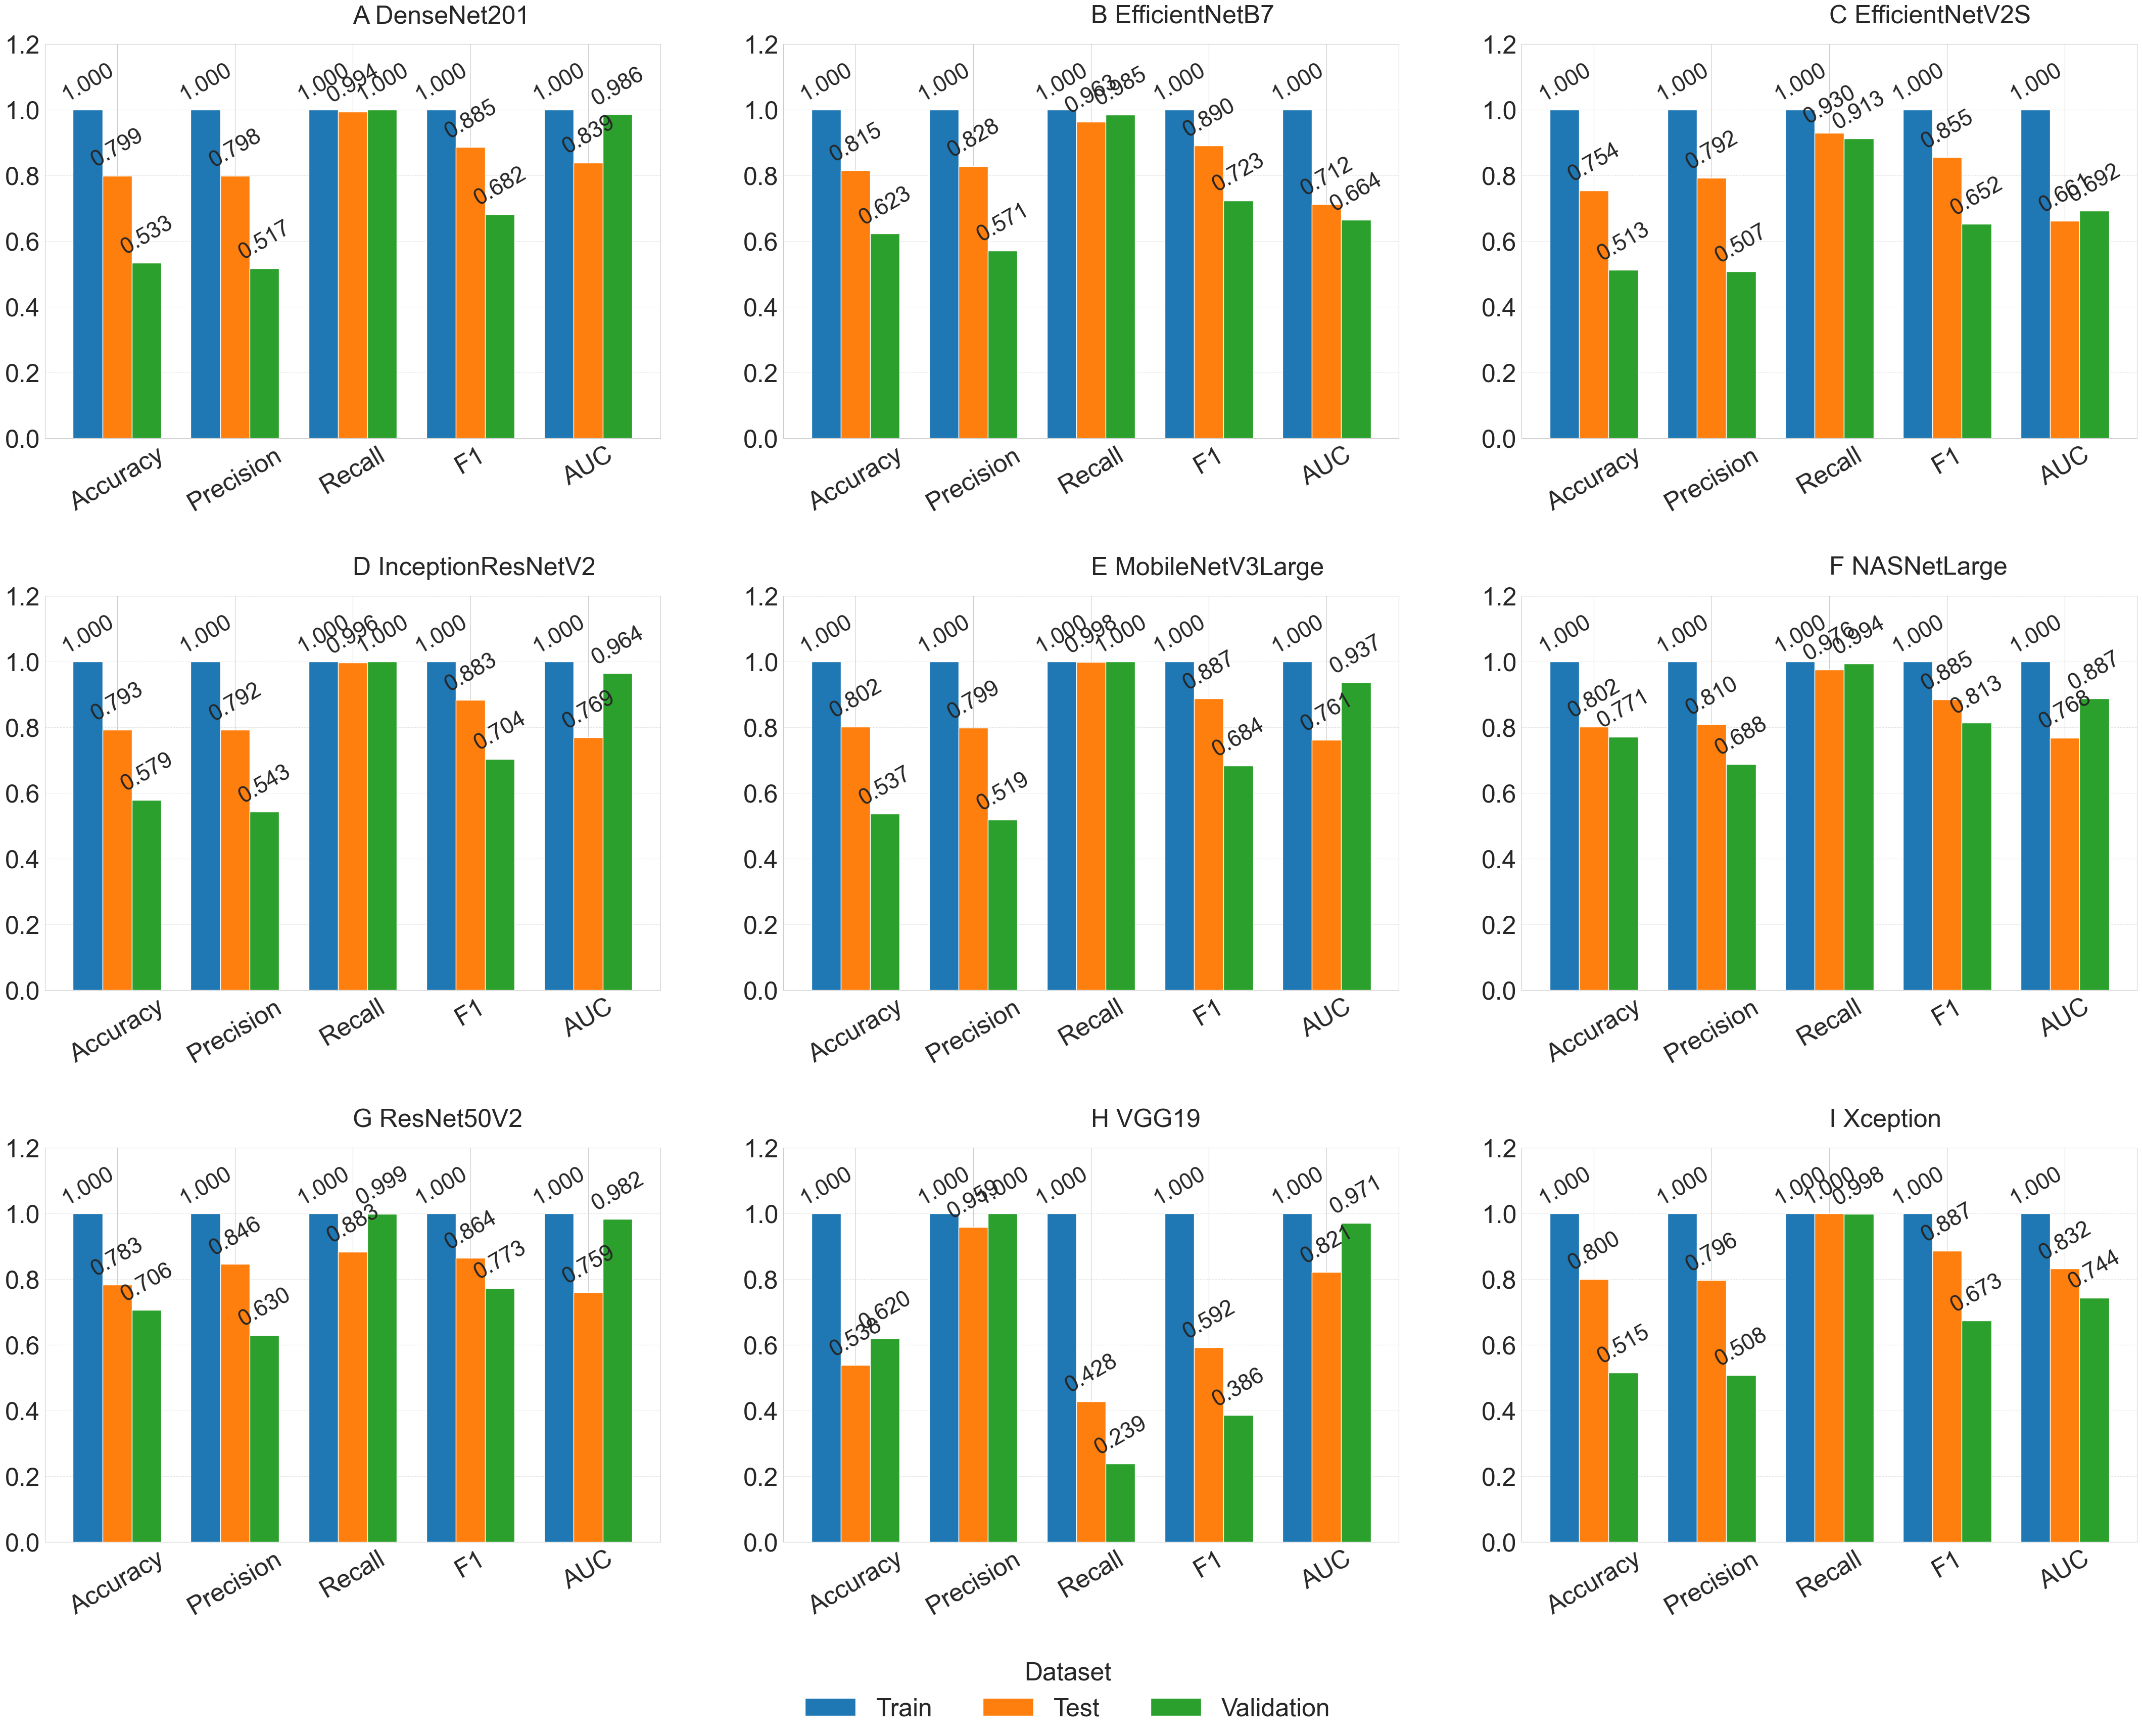

In [15]:
# model metrics

# Import required libraries for data processing, visualization and file management
import pandas as pd
import matplotlib.pyplot as plt
import os

# Set root data path and fixed image save directory (your specified path)
base_path = r'C:\Users\zhd\LungCancer'
save_dir = r'C:\Users\zhd\LungCancer\01.base'
model_folders = ['DenseNet201', 'EfficientNetB7', 'EfficientNetV2S', 
                 'InceptionResNetV2', 'MobileNetV3Large', 'NASNetLarge', 
                 'ResNet50V2', 'VGG19', 'Xception']
subplot_labels = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I']

# Automatically create save folder, avoid path error if folder not exists
os.makedirs(save_dir, exist_ok=True)

# Initialize 3x3 subplot layout with widened horizontal canvas size
fig, axes = plt.subplots(3, 3, figsize=(46, 38))
axes = axes.flatten()

# Define evaluation metrics list and suitable bar width for 3 parallel bars
metrics = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
bar_width = 0.25

# Define three datasets and professional color matching
dataset_names = ['Train', 'Test', 'Validation']
bar_colors = ['#1f77b4', '#ff7f0e', '#2ca02c']

# Iterate each model and plot metrics bar chart in corresponding subplot
for i, (folder, label) in enumerate(zip(model_folders, subplot_labels)):
    # Read evaluation metrics csv file for current model
    file_path = os.path.join(base_path, folder, 'evaluation_metrics.csv')
    df = pd.read_csv(file_path)
    
    # Basic x-axis positions based on metrics count
    x = range(len(metrics))

    # Plot parallel bars for three datasets and add value labels
    for idx, (dataset, color) in enumerate(zip(dataset_names, bar_colors)):
        bar_x = [pos + bar_width * (idx - 1) for pos in x]
        data = df[df['Dataset'] == dataset][metrics].values[0]
        axes[i].bar(bar_x, data, width=bar_width, label=dataset, color=color)
        
        # Add tilted value labels with fontsize 28 for each bar
        for j, (x_pos, value) in enumerate(zip(bar_x, data)):
            axes[i].text(x_pos, value + 0.015, f'{value:.3f}', 
                         ha='center', va='bottom', fontsize=36, rotation=30)
    
    # Set subplot style parameters, unified fontsize 28 for all elements
    axes[i].set_title(f'{label} {folder}', fontsize=36, pad=30, ha='left')
    axes[i].set_xticks(x)
    axes[i].set_xticklabels(metrics, fontsize=36, rotation=30)
    axes[i].set_ylim(0, 1.2)
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)
    axes[i].tick_params(axis='both', labelsize=36)

# Set global legend with consistent fontsize at bottom center
fig.legend(dataset_names, loc='lower center', ncol=3, 
           fontsize=36, title='Dataset', title_fontsize=36,
           bbox_to_anchor=(0.5, 0.015), frameon=False)

# Adjust layout spacing to fit wide canvas and large font size
plt.subplots_adjust(left=0.06, right=0.96, bottom=0.12, top=0.9, 
                    wspace=0.2, hspace=0.4)

# Save high-resolution pdf and png images to your specified fixed directory
pdf_save_path = os.path.join(save_dir, 'model_metrics.pdf')
png_save_path = os.path.join(save_dir, 'model_metrics.png')
plt.savefig(pdf_save_path, dpi=400, bbox_inches='tight')
plt.savefig(png_save_path, dpi=400, bbox_inches='tight')

# Display the visualization result
plt.show()

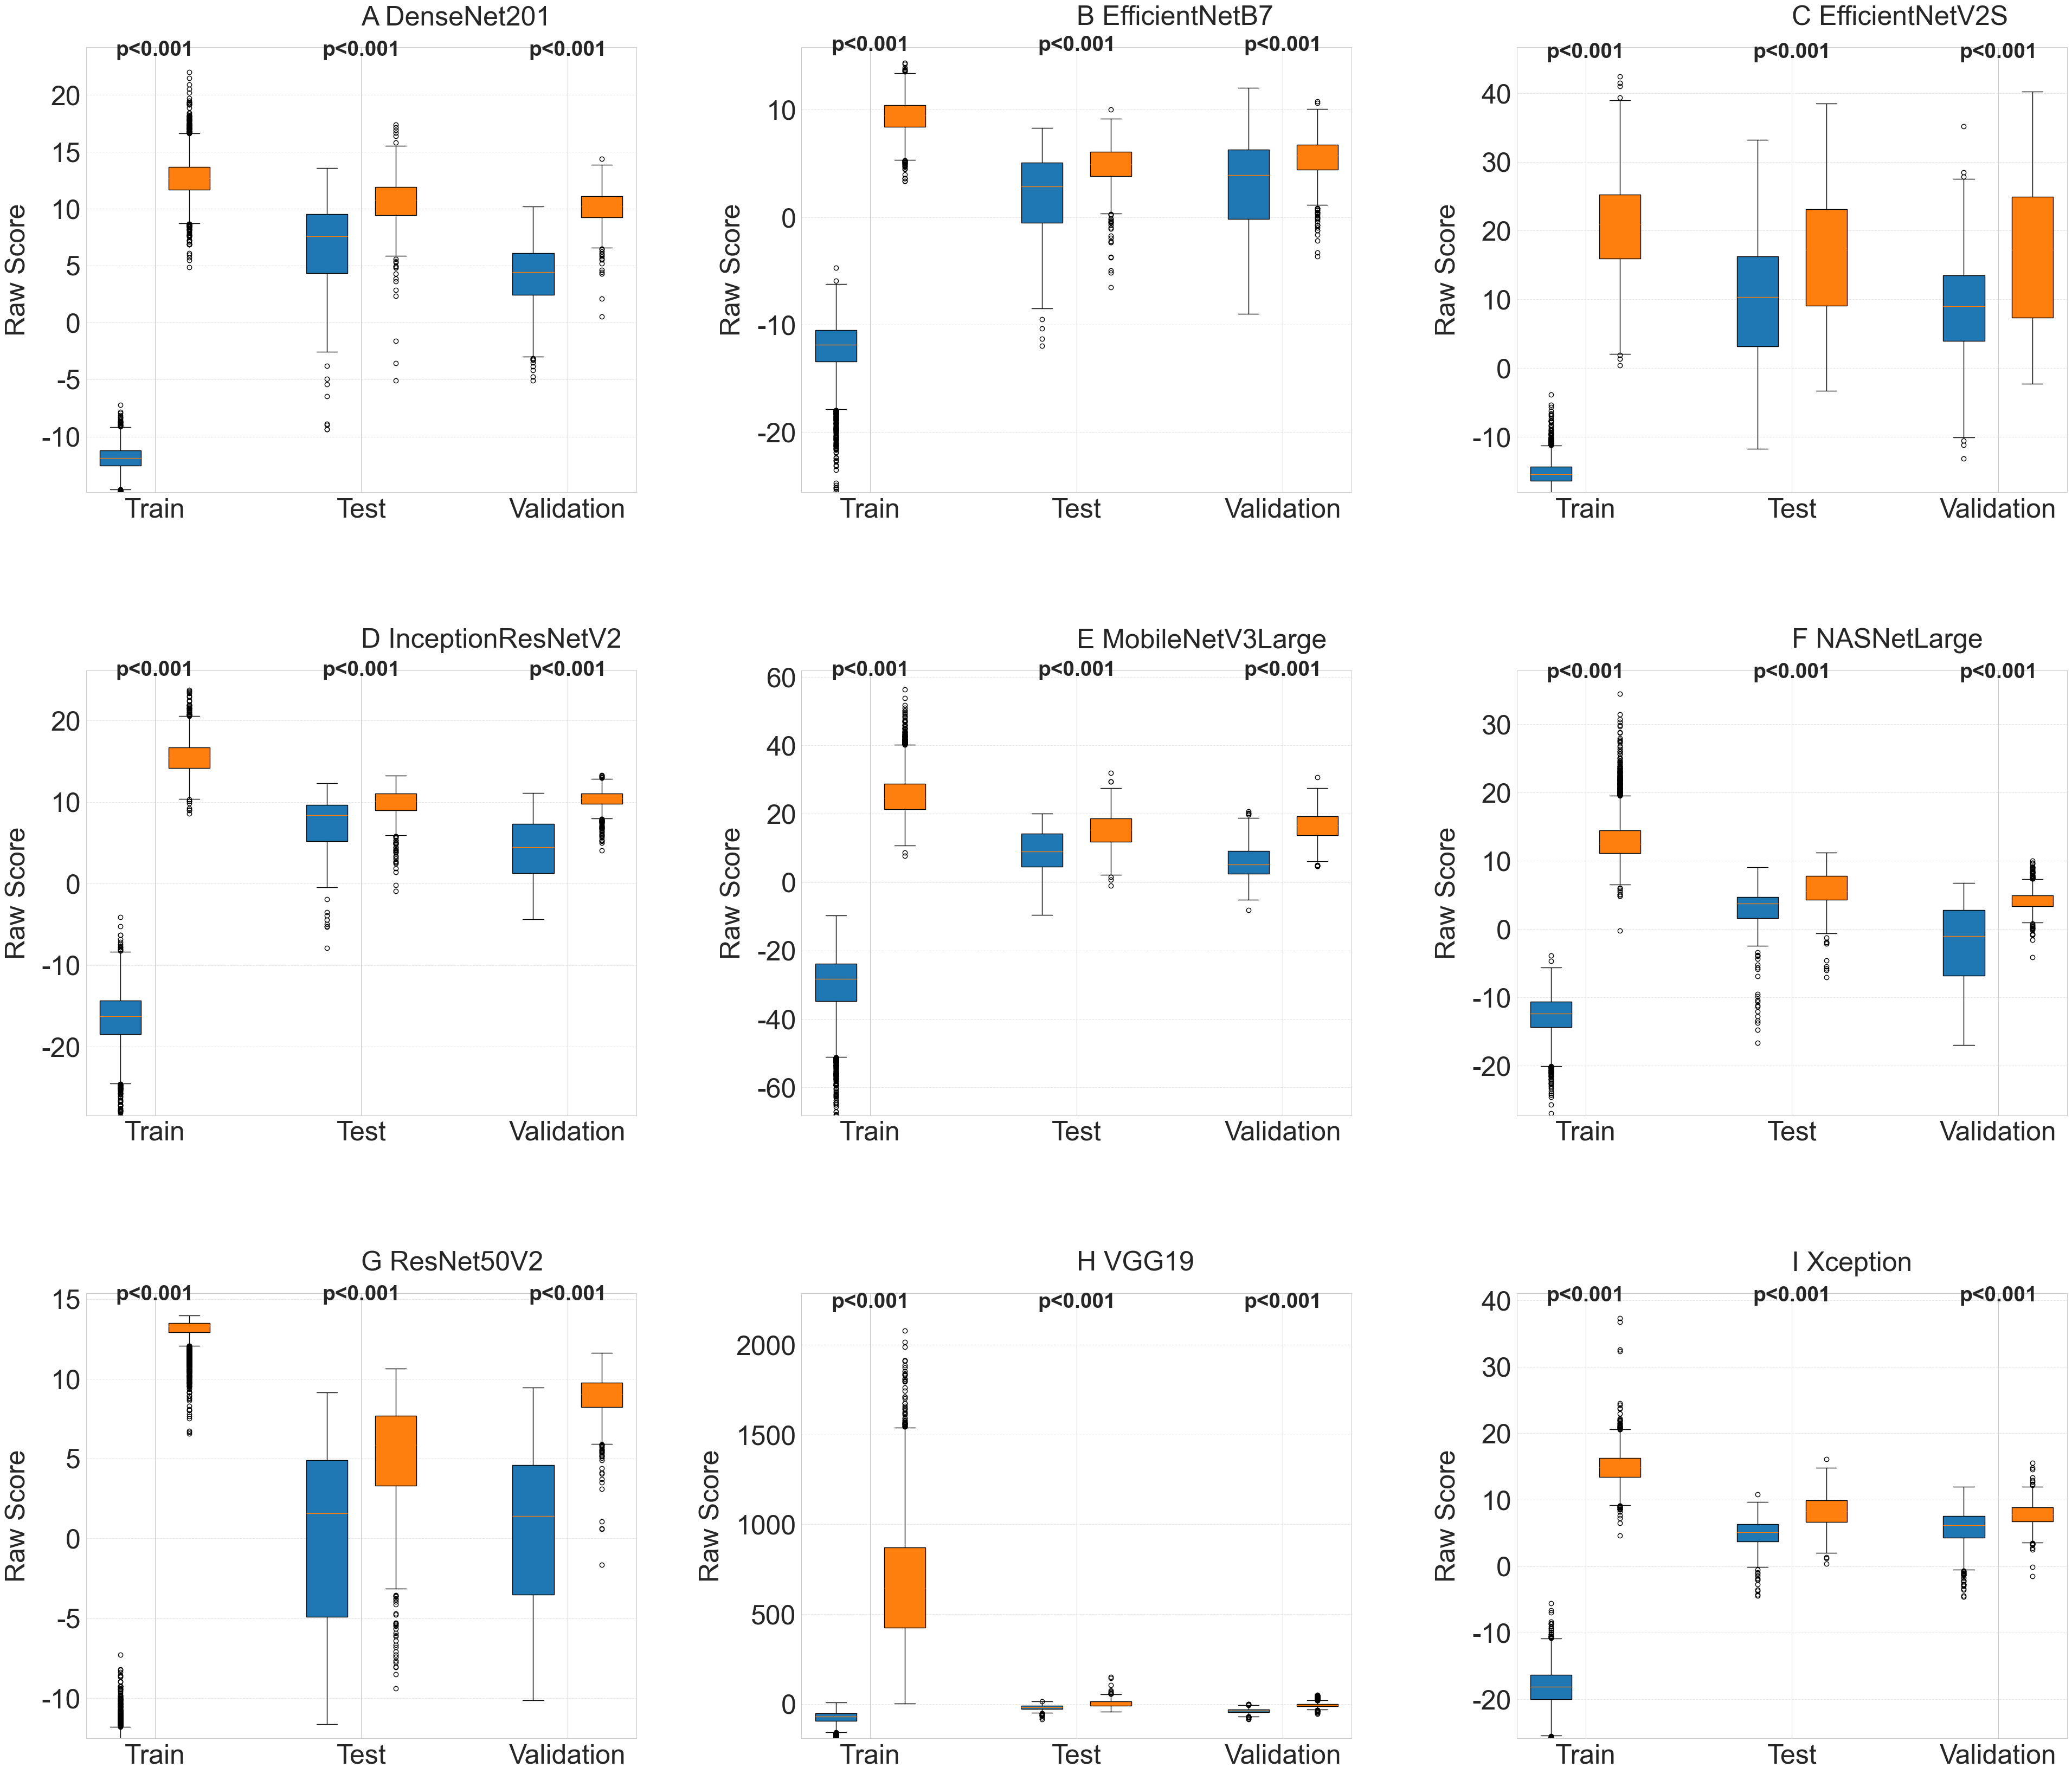

In [17]:
# raw score boxplot

# Import required libraries for data processing, visualization, statistical test and file operation
import pandas as pd
import matplotlib.pyplot as plt
import os
from scipy.stats import mannwhitneyu
import numpy as np

# Basic configuration: set root path, model list, save directory and create folder if not exist
base_path = r'C:\Users\zhd\LungCancer'
model_folders = ['DenseNet201', 'EfficientNetB7', 'EfficientNetV2S', 
                 'InceptionResNetV2', 'MobileNetV3Large', 'NASNetLarge', 
                 'ResNet50V2', 'VGG19', 'Xception']
subplot_labels = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I']
save_dir = os.path.join(base_path, '01.base')
os.makedirs(save_dir, exist_ok=True)

# Visual style config: fixed color palette for binary True_Label, 3 datasets list
colors = ['#1f77b4', '#ff7f0e']
dataset_names = ['Train', 'Test', 'Validation']

# Initialize 3x3 subplot layout with large canvas size for big font display
fig, axes = plt.subplots(3, 3, figsize=(42, 40))
axes = axes.flatten()

# Core loop: iterate each model and plot boxplot in corresponding subplot
for i, (folder, label) in enumerate(zip(model_folders, subplot_labels)):
    # Load prediction data from csv file for current model
    file_path = os.path.join(base_path, folder, 'all_predictions.csv')
    df = pd.read_csv(file_path)
    
    # Check binary classification of True_Label, raise error if not two unique values
    true_labels = sorted(df['True_Label'].unique())
    if len(true_labels) != 2:
        raise ValueError(f"Model {folder} has non-binary True_Label, check data")
    
    # Initialize variables for boxplot data, position and statistical test results
    box_data = []
    positions = []
    current_pos = 1
    u_test_results = []

    # Traverse 3 datasets, extract data and conduct U-test for each dataset
    for dataset in dataset_names:
        df_dataset = df[df['Dataset'] == dataset]
        
        # Extract Raw_Score by True_Label for boxplot
        for label_idx, tl in enumerate(true_labels):
            data = df_dataset[df_dataset['True_Label'] == tl]['Raw_Score'].values
            box_data.append(data)
            positions.append(current_pos)
            current_pos += 1
        
        # Mann-Whitney U test between two True_Label groups in current dataset
        data0 = df_dataset[df_dataset['True_Label'] == true_labels[0]]['Raw_Score'].values
        data1 = df_dataset[df_dataset['True_Label'] == true_labels[1]]['Raw_Score'].values
        stat, p = mannwhitneyu(data0, data1, alternative='two-sided')
        u_test_results.append((dataset, p))
        
        current_pos += 1  # Add space between different datasets

    # Plot boxplot with filled color, set box width
    bp = axes[i].boxplot(box_data, positions=positions, patch_artist=True, widths=0.6)
    
    # Assign color to each box by True_Label category (cycle color palette)
    for patch_idx, patch in enumerate(bp['boxes']):
        patch.set_facecolor(colors[patch_idx % 2])

    # Add U-test p-value annotation above each dataset's boxplots
    for idx, (dataset, p) in enumerate(u_test_results):
        y_pos = max([np.max(data) for data in box_data]) * 1.05
        x_pos = positions[idx*2] + 0.5
        p_text = f'p={p:.3f}' if p >= 0.001 else 'p<0.001'
        axes[i].text(x_pos, y_pos, f'{p_text}', 
                     ha='center', va='bottom', fontsize=28, fontweight='bold')

    # Subplot style configuration with unified large font size
    axes[i].set_title(f'{label} {folder}', fontsize=36, pad=30, ha='left')
    axes[i].set_xticks([1.5, 4.5, 7.5])  # X ticks aligned with 3 datasets
    axes[i].set_xticklabels(dataset_names, fontsize=36)
    axes[i].tick_params(axis='y', labelsize=36)
    axes[i].set_ylabel('Raw Score', fontsize=36, labelpad=15)
    axes[i].grid(axis='y', linestyle='--', alpha=0.5)
    axes[i].set_ylim(min([np.min(data) for data in box_data])*0.9, 
                     max([np.max(data) for data in box_data])*1.1)

# Adjust subplot spacing to avoid overlap with large font elements
plt.subplots_adjust(left=0.08, right=0.95, bottom=0.12, top=0.9, 
                    wspace=0.3, hspace=0.4)

# Save high-resolution figures to the specified directory (pdf + png)
pdf_path = os.path.join(save_dir, 'raw_score_boxplot.pdf')
png_path = os.path.join(save_dir, 'raw_score_boxplot.png')
plt.savefig(pdf_path, dpi=400, bbox_inches='tight')
plt.savefig(png_path, dpi=400, bbox_inches='tight')

# Display the visualization
plt.show()

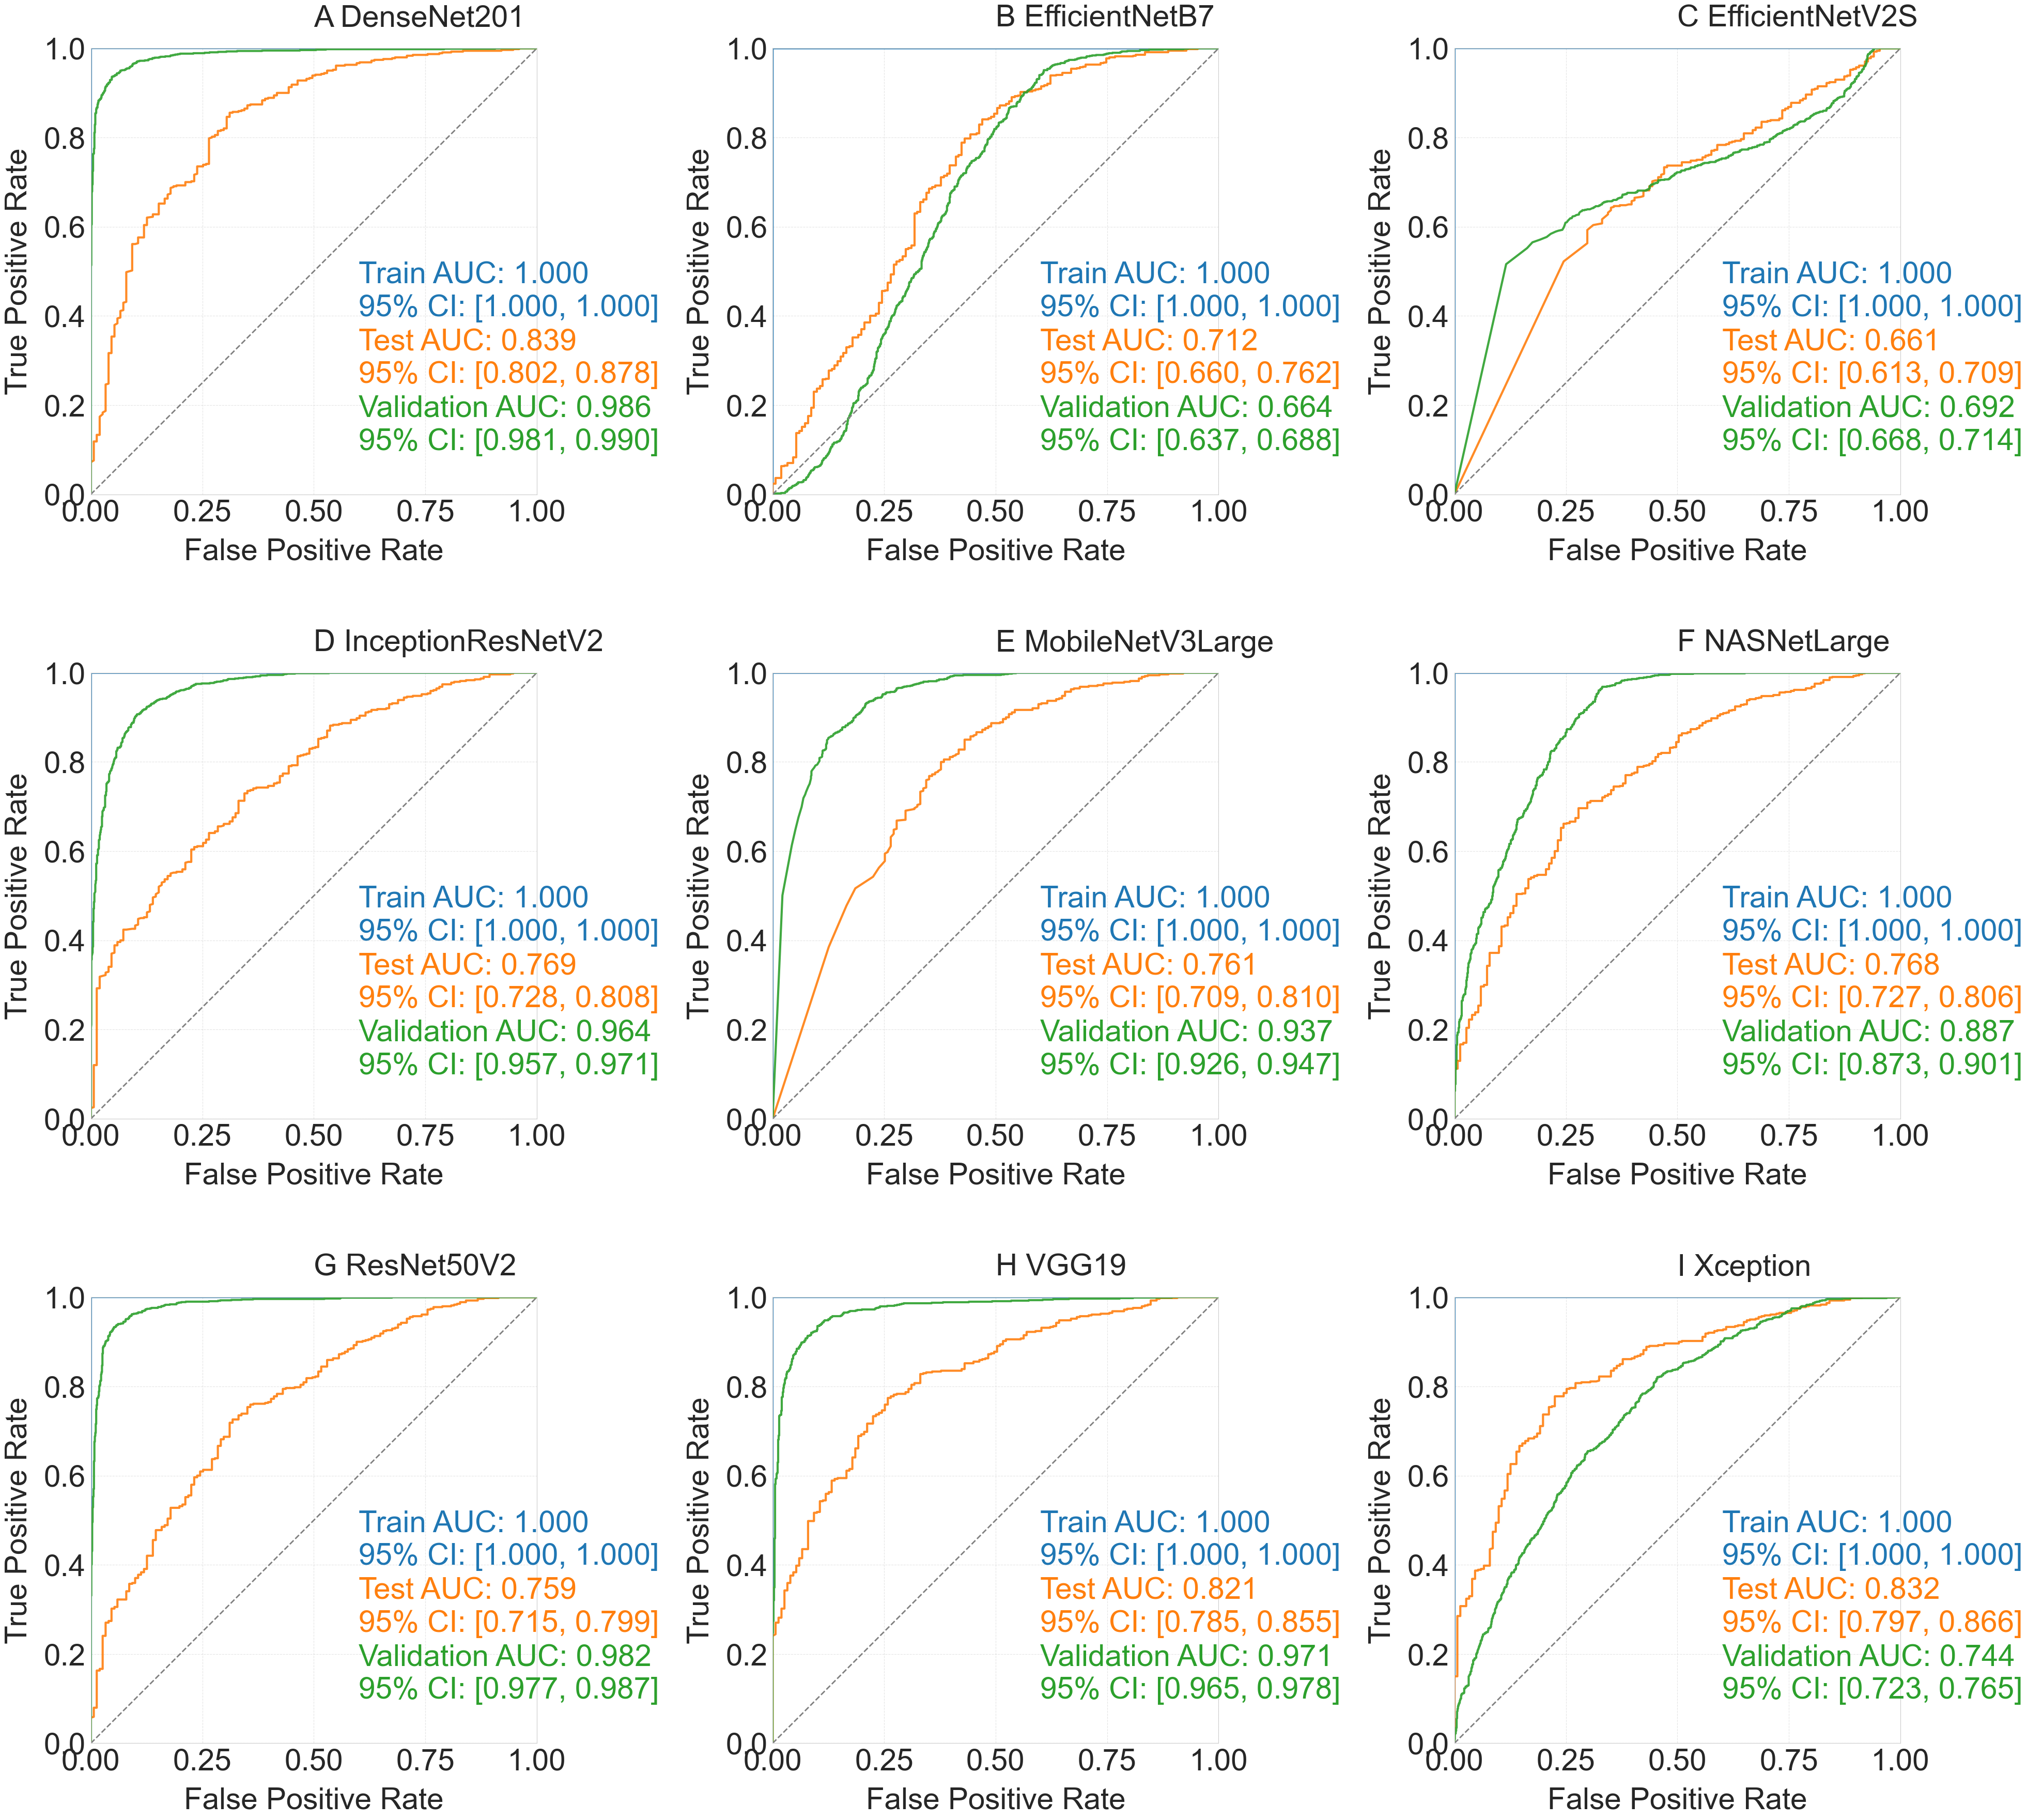

In [21]:
# roc curves

# Import libraries: data processing, visualization, metrics calculation, bootstrap sampling
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.utils import resample

# Basic configuration: root path, model list, subplot labels, auto create save directory
base_path = r'C:\Users\zhd\LungCancer'
model_folders = ['DenseNet201', 'EfficientNetB7', 'EfficientNetV2S', 
                 'InceptionResNetV2', 'MobileNetV3Large', 'NASNetLarge', 
                 'ResNet50V2', 'VGG19', 'Xception']
subplot_labels = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I']
save_dir = os.path.join(base_path, '01.base')
os.makedirs(save_dir, exist_ok=True)

# Visual style config: color mapping for 3 datasets, consistent professional palette
colors = {'Train': '#1f77b4', 'Test': '#ff7f0e', 'Validation': '#2ca02c'}
random_color = '#808080'
line_width = 3

# Bootstrap parameters for AUC 95% Confidence Interval calculation
bootstrap_n = 1000
ci_alpha = 0.95

# Initialize 3x3 subplot layout with large canvas for big font display
fig, axes = plt.subplots(3, 3, figsize=(42, 40))
axes = axes.flatten()

# Core function: calculate AUC 95% CI using bootstrap resampling method
def auc_ci(y_true, y_prob, n_boot=1000, alpha=0.95):
    n = len(y_true)
    boot_aucs = []
    for _ in range(n_boot):
        idx = resample(range(n), replace=True, n_samples=n)
        y_true_boot = y_true[idx]
        y_prob_boot = y_prob[idx]
        if len(np.unique(y_true_boot)) < 2:
            continue
        boot_aucs.append(roc_auc_score(y_true_boot, y_prob_boot))
    lower = np.percentile(boot_aucs, (1 - alpha) / 2 * 100)
    upper = np.percentile(boot_aucs, (1 + alpha) / 2 * 100)
    return lower, upper

# Core loop: iterate each model, calculate ROC/AUC/CI and plot ROC curves
for i, (folder, label) in enumerate(zip(model_folders, subplot_labels)):
    # Load prediction probability and binary label data
    file_path = os.path.join(base_path, folder, 'all_predictions.csv')
    df = pd.read_csv(file_path)
    
    # Validate binary classification label constraint (0 or 1 only)
    if not set(df['True_Label'].unique()).issubset({0, 1}):
        raise ValueError(f"Model {folder} requires binary True_Label (0/1) values only")
    
    # Initialize plot handles and labels for independent subplot legend
    plot_handles = []
    plot_labels = []

    # Define annotation Y positions for 3 datasets (no overlap, fixed order)
    annot_y_pos = {'Train':0.40, 'Test':0.25, 'Validation':0.10}
    # Iterate 3 datasets and plot ROC curves separately
    dataset_names = ['Train', 'Test', 'Validation']
    for dataset in dataset_names:
        df_sub = df[df['Dataset'] == dataset].copy()
        y_true = df_sub['True_Label'].values
        y_prob = df_sub['Probability'].values
        
        # Calculate ROC curve points, AUC value and 95% CI
        fpr, tpr, _ = roc_curve(y_true, y_prob)
        auc_score = roc_auc_score(y_true, y_prob)
        auc_lower, auc_upper = auc_ci(y_true, y_prob, n_boot=bootstrap_n)
        
        # Plot ROC curve for current dataset
        line, = axes[i].plot(fpr, tpr, color=colors[dataset], linewidth=line_width, alpha=0.9)
        plot_handles.append(line)
        # plot_labels.append(f'{dataset}')

        # Annotate AUC value + 95% CI with white background box (anti-overlap)
        annot_text = f'{dataset} AUC: {auc_score:.3f}\n95% CI: [{auc_lower:.3f}, {auc_upper:.3f}]'
        axes[i].text(0.6, annot_y_pos[dataset], annot_text, fontsize=42, color=colors[dataset]) #,
                    # bbox=dict(facecolor='white', edgecolor='gray', alpha=0.8, boxstyle='round,pad=0.5'))

    # Plot random guess baseline (AUC=0.5, diagonal dashed line)
    random_line, = axes[i].plot([0,1], [0,1], color=random_color, linestyle='--', linewidth=2)
    plot_handles.append(random_line)
    # plot_labels.append('Random Guess (AUC=0.500)')

    # Uniform subplot style configuration (all font size 28 standard)
    axes[i].set_title(f'{label} {folder}', fontsize=42, pad=30, ha='left')
    axes[i].set_xlabel('False Positive Rate', fontsize=42, labelpad=15)
    axes[i].set_ylabel('True Positive Rate', fontsize=42, labelpad=15)
    axes[i].set_xlim(0, 1)
    axes[i].set_ylim(0, 1)
    axes[i].tick_params(axis='both', labelsize=42)
    axes[i].grid(linestyle='--', alpha=0.5)
    axes[i].set_aspect('equal') # Critical: equal axis ratio for 45-degree baseline
    # Add independent legend for each subplot (lower right, no frame)
    axes[i].legend(plot_handles, plot_labels, fontsize=42, loc='lower right', frameon=False)

# Adjust subplot spacing to avoid overlap with large font and annotations
plt.subplots_adjust(left=0.08, right=0.95, bottom=0.1, top=0.92, wspace=0.3, hspace=0.4)

# Save high-resolution PDF/PNG figures to the specified directory
pdf_path = os.path.join(save_dir, 'roc_curves.pdf')
png_path = os.path.join(save_dir, 'roc_curves.png')
plt.savefig(pdf_path, dpi=400, bbox_inches='tight')
plt.savefig(png_path, dpi=400, bbox_inches='tight')

# Display the final ROC plots
plt.show()